# 🧠 MRI Görüntülerinden Beyin Tümörü Tespiti ve Sınıflandırılması
## Derin Öğrenme Tabanlı Çok Modelli Ensemble Sistemi

---

| Alan | Bilgi |
|------|-------|
| **Öğrenciler** | 230710016 – Muhammet Miraç KESER · 230710054 – Cansu Naz KALKAN |
| **Ders** | Derin Öğrenme ve Görüntü İşleme |
| **Proje** | MRI Beyin Tümörü Tespiti & Sınıflandırması |
| **Yöntemler** | EfficientNetB3 · DenseNet201 · Xception · Weighted Soft-Voting Ensemble |
| **XAI** | Grad-CAM++ · Sınıf Aktivasyon Haritası |

---

### Proje Özeti

Bu proje; MRI görüntülerinden derin öğrenme ile beyin tümörü tespiti ve tür sınıflandırması yapmayı hedeflemektedir.
Projede **4 sınıf** ele alınmıştır: `glioma`, `meningioma`, `notumor`, `pituitary`.

**Temel Yenilikler:**
- Önceki çalışmaya kıyasla daha güçlü backbone'lar (EfficientNetB3, DenseNet201, Xception)
- Test zamanı veri artırma — TTA (Test-Time Augmentation)
- Ağırlıklı Yumuşak Oylama Ensemble (Weighted Soft-Voting)
- Cosine Annealing öğrenme hızı planlaması
- Label Smoothing kayıp fonksiyonu (aşırı öğrenmeyi önler)
- Gelişmiş veri artırma (CLAHE kontrast iyileştirme dahil)
- Grad-CAM++ görselleştirme
- Kapsamlı grafik ve metrik analizi


## 1. Kütüphane İmportları ve Ortam Hazırlığı

In [2]:
# ============================================================
# 230710016 – Muhammet Miraç KESER
# 230710054 – Cansu Naz KALKAN
# Proje: MRI Beyin Tümörü Tespiti ve Sınıflandırılması
# ============================================================

# ── Standart kütüphaneler ──────────────────────────────────
import os
import json
import time
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
from pathlib import Path
from itertools import cycle

# ── Sklearn ───────────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import label_binarize

# ── TensorFlow / Keras ────────────────────────────────────
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau,
    ModelCheckpoint, TensorBoard, LambdaCallback
)
from tensorflow.keras.applications import (
    EfficientNetB3, DenseNet201, Xception
)
from tensorflow.keras.layers import (
    Dense, GlobalAveragePooling2D, Dropout,
    BatchNormalization, Activation, Input,
    Multiply, Reshape, Lambda
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.regularizers import l2

# ── Uyarıları bastır ──────────────────────────────────────
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# ── Tekrar üretilebilirlik için tohum sabitleme ───────────
# Farklı çalıştırmalarda aynı sonuçları almak için
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── GPU yapılandırması ────────────────────────────────────
# GPU varsa bellek büyümesini dinamik olarak etkinleştir
try:
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ {len(gpus)} GPU bulundu ve yapılandırıldı.")
    else:
        print("⚠️  GPU bulunamadı — CPU üzerinde devam ediliyor.")
except RuntimeError as e:
    print(f"GPU yapılandırma hatası: {e}")

print(f"TensorFlow Sürümü : {tf.__version__}")
print(f"Keras Sürümü      : {tf.keras.__version__}")

# ── Görsel stil ayarları ──────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'font.family': 'DejaVu Sans',
})
sns.set_theme(style="whitegrid", palette="muted")

# ── Proje sabitleri ───────────────────────────────────────
IMG_SIZE   = (224, 224)   # Tüm backbone'lar 224×224 destekler
BATCH_SIZE = 32
SEED       = 42
NUM_CLASSES = 4           # glioma, meningioma, notumor, pituitary

print("\n✅ Tüm kütüphaneler başarıyla yüklendi.")



✅ 1 GPU bulundu ve yapılandırıldı.
TensorFlow Sürümü : 2.16.2
Keras Sürümü      : 3.14.1

✅ Tüm kütüphaneler başarıyla yüklendi.


## 2. Veri Yükleme ve Keşifsel Veri Analizi (EDA)

Kullanılan veri seti: **Brain Tumor MRI Dataset** (Kaggle).  
Yapısı: `Training/` ve `Testing/` alt klasörleri, her biri 4 sınıf içerir.

> 📁 Veri seti yolu kendi ortamınıza göre güncelleyin (`TRAIN_DIR` / `TEST_DIR`).


In [3]:
# ── Veri seti yolları ─────────────────────────────────────
# Kaggle'dan indirilen veri seti klasör yapısı:
# BrainTumorDataset/
#   Training/  → glioma/ meningioma/ notumor/ pituitary/
#   Testing/   → glioma/ meningioma/ notumor/ pituitary/

import os

TRAIN_DIR = '/Users/mirackeser/Desktop/proje/BrainTumorDataset/Training'
TEST_DIR  = '/Users/mirackeser/Desktop/proje/BrainTumorDataset/Testing'

print("TRAIN_DIR var mı?", os.path.exists(TRAIN_DIR))
print("TEST_DIR  var mı?", os.path.exists(TEST_DIR))

def load_dataset(data_dir: str, img_size: tuple = (224, 224)) -> tuple:
    """
    Belirtilen dizindeki MRI görüntülerini yükler ve ön işler.

    Yapılan işlemler:
    1. Gizli dosyalar (.DS_Store vb.) atlanır
    2. Görüntüler BGR→RGB dönüşümü ile okunur
    3. CLAHE (Kontrast Sınırlı Uyarlamalı Histogram Eşitleme) uygulanır
       → Düşük kontrastlı MRI görüntülerinde tümör sınırlarını belirginleştirir
    4. Birim normalizasyon [0-1] yapılır
    """
    images, labels = [], []

    # Gizli ve sistem dosyalarını atla
    classes = sorted([
        d for d in os.listdir(data_dir)
        if os.path.isdir(os.path.join(data_dir, d)) and not d.startswith('.')
    ])
    class_to_idx = {cls: i for i, cls in enumerate(classes)}

    # CLAHE nesnesi — kontrast iyileştirme için
    # clipLimit: kontrast yükseltme sınırı, gürültüyü önler
    # tileGridSize: piksellerin bölündüğü ızgara boyutu
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    for cls_name in classes:
        cls_dir = os.path.join(data_dir, cls_name)
        for fname in os.listdir(cls_dir):
            if fname.startswith('.'):           # sistem dosyalarını atla
                continue
            fpath = os.path.join(cls_dir, fname)
            try:
                img_bgr = cv2.imread(fpath)
                if img_bgr is None:
                    continue

                # BGR → RGB dönüşümü (OpenCV varsayılan olarak BGR okur)
                img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

                # Boyut standardizasyonu
                img_rgb = cv2.resize(img_rgb, img_size)

                # CLAHE: LAB renk uzayında sadece L kanalına uygula
                # Bu yöntem renk bilgisini bozmadan parlaklık kontrastını iyileştirir
                lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
                l_ch, a_ch, b_ch = cv2.split(lab)
                l_ch = clahe.apply(l_ch)
                lab_eq = cv2.merge((l_ch, a_ch, b_ch))
                img_final = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)

                images.append(img_final)
                labels.append(class_to_idx[cls_name])

            except Exception as e:
                print(f"  ⚠️  Dosya atlandı: {fpath} — {e}")

    # Numpy dizilerine çevir ve normalize et [0, 1]
    X = np.array(images, dtype='float32') / 255.0
    y = np.array(labels, dtype='int32')
    return X, y, classes

# ── Verileri yükle ────────────────────────────────────────
print("📂 Eğitim verileri yükleniyor...")
X_train_full, y_train_full, CLASSES = load_dataset(TRAIN_DIR, IMG_SIZE)
print(f"   → {X_train_full.shape[0]} görüntü yüklendi")

print("\n📂 Test verileri yükleniyor...")
X_test, y_test_raw, _ = load_dataset(TEST_DIR, IMG_SIZE)
print(f"   → {X_test.shape[0]} görüntü yüklendi")

# ── Sınıf bilgisi ────────────────────────────────────────
print(f"\n🏷️  Sınıflar       : {CLASSES}")
print(f"📐 Görüntü boyutu : {X_train_full.shape[1:]}")
print(f"🔢 Toplam eğitim  : {X_train_full.shape[0]}")
print(f"🔢 Toplam test    : {X_test.shape[0]}")


TRAIN_DIR var mı? True
TEST_DIR  var mı? True
📂 Eğitim verileri yükleniyor...
   → 5600 görüntü yüklendi

📂 Test verileri yükleniyor...
   → 1600 görüntü yüklendi

🏷️  Sınıflar       : ['glioma', 'meningioma', 'notumor', 'pituitary']
📐 Görüntü boyutu : (224, 224, 3)
🔢 Toplam eğitim  : 5600
🔢 Toplam test    : 1600


### 2.1 Sınıf Dağılımı ve Örnek Görüntüler

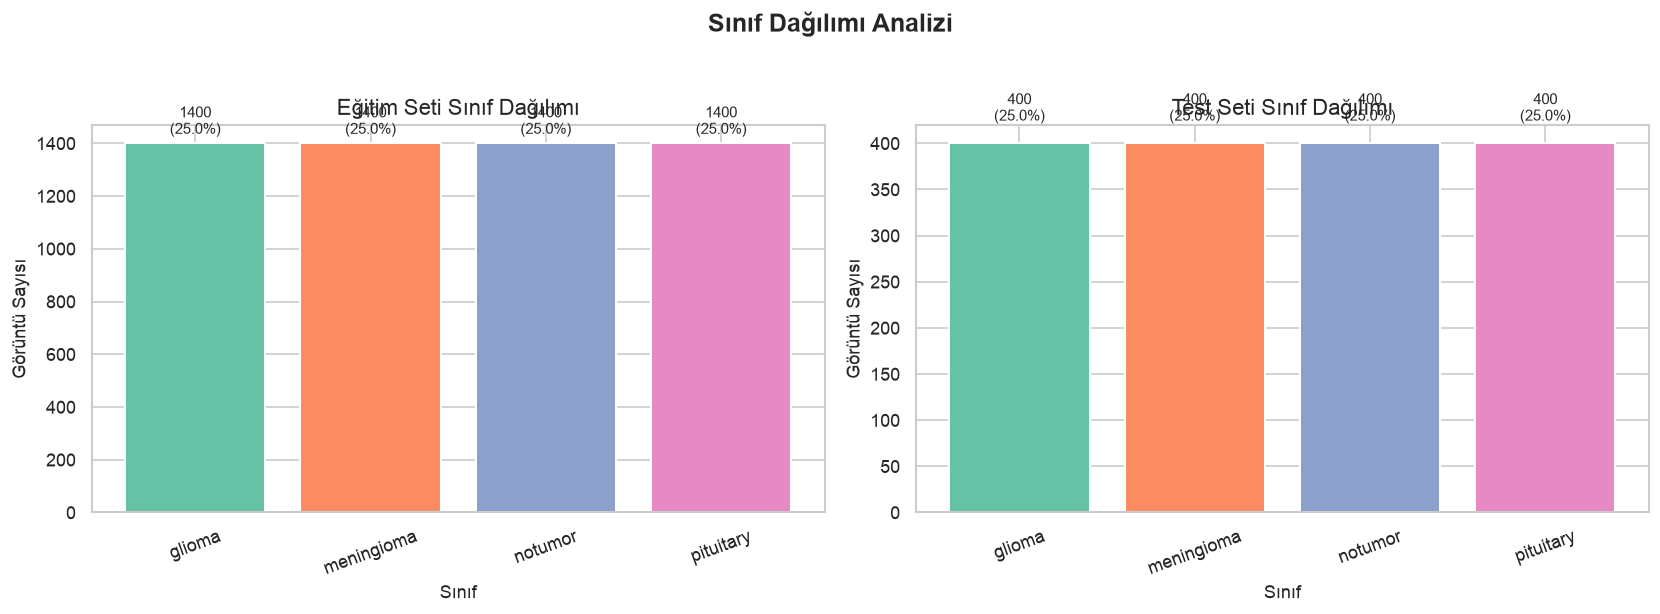

✅ Grafik kaydedildi: class_distribution.png

📊 Sınıf Dağılımı Özeti:
   glioma      : 1400 görüntü (25.0%)
   meningioma  : 1400 görüntü (25.0%)
   notumor     : 1400 görüntü (25.0%)
   pituitary   : 1400 görüntü (25.0%)


In [4]:
# ── Sınıf dağılımı görselleştirmesi ──────────────────────
# Eğitim ve test setindeki sınıf dengesini kontrol ederiz.
# Dengesiz veri → eğitim sırasında class_weight kullanımını tetikler.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Sınıf Dağılımı Analizi', fontsize=15, fontweight='bold', y=1.02)

colors = sns.color_palette("Set2", NUM_CLASSES)

for ax, (data_y, title) in zip(axes, [
    (y_train_full, 'Eğitim Seti'),
    (y_test_raw,   'Test Seti')
]):
    unique, counts = np.unique(data_y, return_counts=True)
    bars = ax.bar(CLASSES, counts, color=colors, edgecolor='white', linewidth=1.2)
    ax.set_title(f'{title} Sınıf Dağılımı', fontsize=13)
    ax.set_xlabel('Sınıf', fontsize=11)
    ax.set_ylabel('Görüntü Sayısı', fontsize=11)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=20)

    # Her barın üstüne sayı yaz
    for bar, cnt in zip(bars, counts):
        ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            f'{cnt}\n({cnt/sum(counts)*100:.1f}%)',
            ha='center', va='bottom', fontsize=9
        )

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik kaydedildi: class_distribution.png")

# ── Sınıf dengesizliği özeti ──────────────────────────────
print("\n📊 Sınıf Dağılımı Özeti:")
train_unique, train_counts = np.unique(y_train_full, return_counts=True)
for cls_idx, cnt in zip(train_unique, train_counts):
    print(f"   {CLASSES[cls_idx]:12s}: {cnt:4d} görüntü ({cnt/len(y_train_full)*100:.1f}%)")


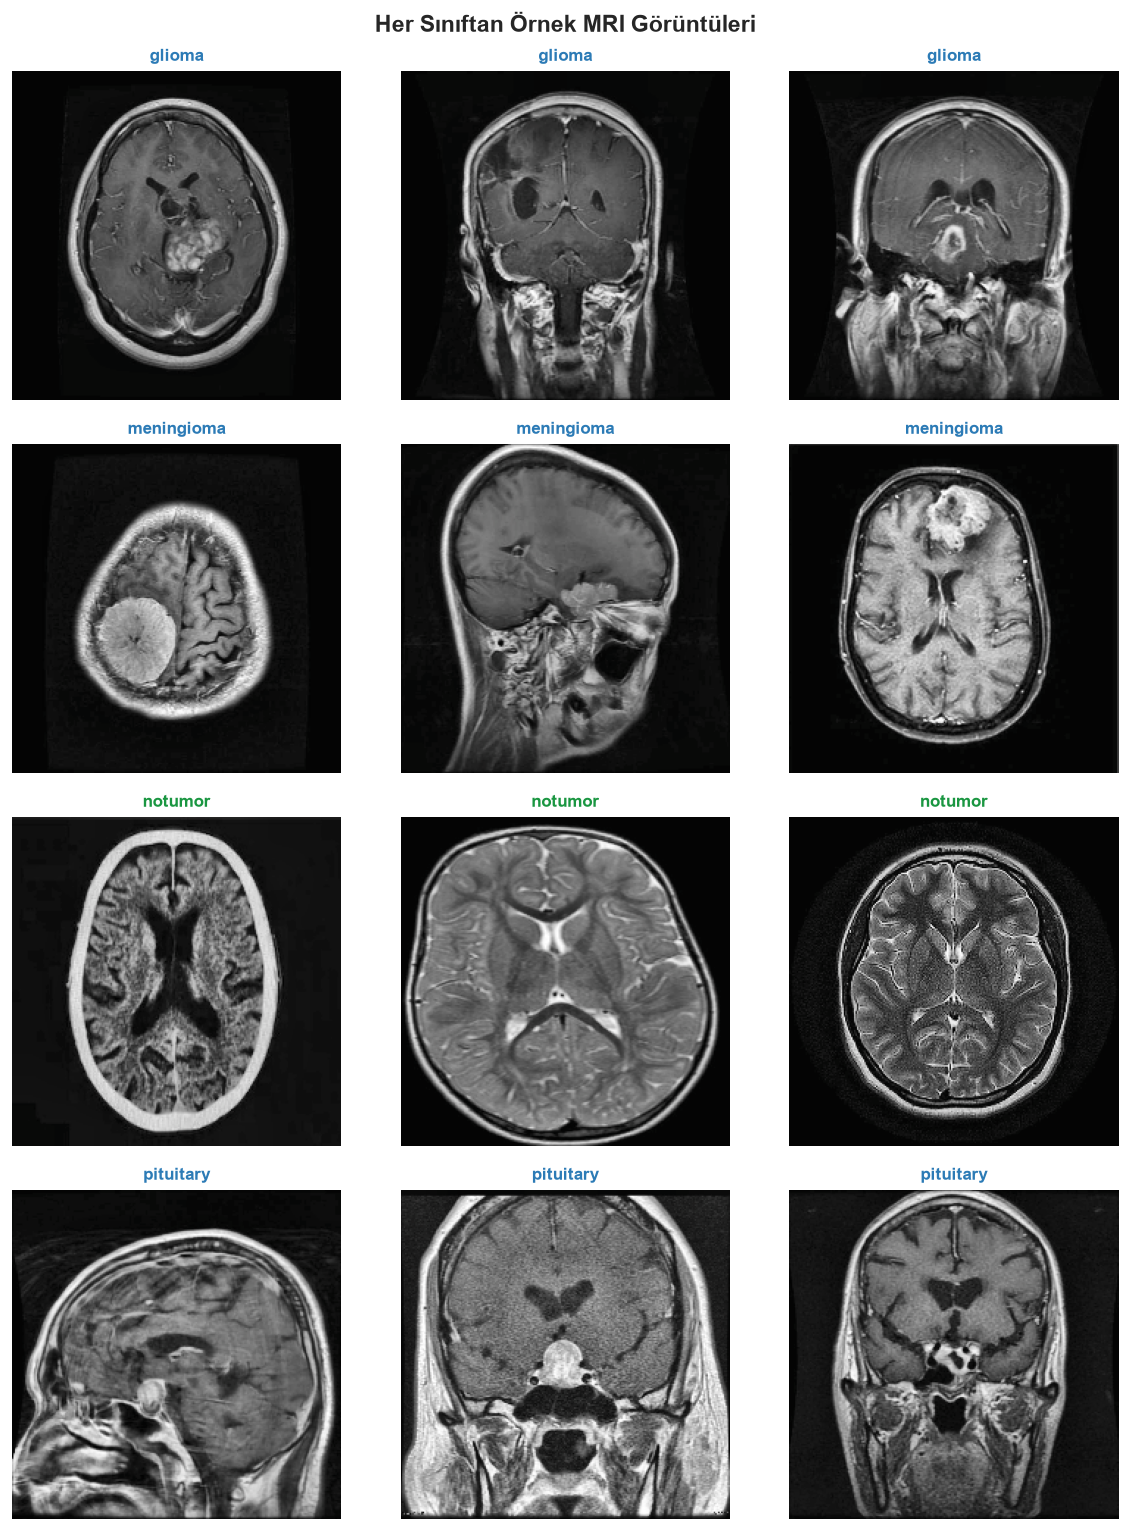

✅ Grafik kaydedildi: sample_images.png


In [5]:
# ── Her sınıftan 3 örnek görüntü göster ──────────────────
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(10, 13))
fig.suptitle('Her Sınıftan Örnek MRI Görüntüleri', fontsize=14, fontweight='bold')

for cls_idx, cls_name in enumerate(CLASSES):
    # İlgili sınıfa ait indeksleri bul
    cls_indices = np.where(y_train_full == cls_idx)[0]
    # Rastgele 3 örnek seç
    sample_idx = np.random.choice(cls_indices, 3, replace=False)

    for col, idx in enumerate(sample_idx):
        ax = axes[cls_idx, col]
        ax.imshow(X_train_full[idx])
        ax.set_title(f'{cls_name}', fontsize=10, fontweight='bold',
                     color='#2c7bb6' if cls_name != 'notumor' else '#1a9641')
        ax.axis('off')

plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik kaydedildi: sample_images.png")


## 3. Veri Hazırlama

### 3.1 Eğitim/Doğrulama Bölmesi ve One-Hot Encoding


In [6]:
# ── One-Hot Encoding ─────────────────────────────────────
# Kategorik etiketleri sinir ağı için uygun formata çevirir
# Örn: sınıf 2 → [0, 0, 1, 0]
y_train_cat = to_categorical(y_train_full, num_classes=NUM_CLASSES)
y_test_cat  = to_categorical(y_test_raw,   num_classes=NUM_CLASSES)

# ── Eğitim/Doğrulama bölmesi (%80/%20) ──────────────────
# stratify=y_train_cat → sınıf oranlarını korur
X_train, X_val, y_train_cat, y_val_cat = train_test_split(
    X_train_full, y_train_cat,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Etiket dizilerini de saklayalım (metriklerde kullanılacak)
y_train_raw = np.argmax(y_train_cat, axis=1)
y_val_raw   = np.argmax(y_val_cat,   axis=1)

print("📊 Veri Seti Boyutları:")
print(f"   Eğitim   : {X_train.shape[0]:5d} görüntü  {X_train.shape[1:]}")
print(f"   Doğrulama: {X_val.shape[0]:5d} görüntü  {X_val.shape[1:]}")
print(f"   Test     : {X_test.shape[0]:5d} görüntü  {X_test.shape[1:]}")
print(f"\n   Etiket şekli (eğitim): {y_train_cat.shape}")


📊 Veri Seti Boyutları:
   Eğitim   :  4480 görüntü  (224, 224, 3)
   Doğrulama:  1120 görüntü  (224, 224, 3)
   Test     :  1600 görüntü  (224, 224, 3)

   Etiket şekli (eğitim): (4480, 4)


### 3.2 Gelişmiş Veri Artırma (Data Augmentation)

Veri artırma, eğitim sırasında her görüntüye rastgele dönüşümler uygulayarak
modelin genelleme kapasitesini artırır ve aşırı öğrenmeyi (overfitting) önler.


✅ Veri artırma jeneratörleri oluşturuldu.


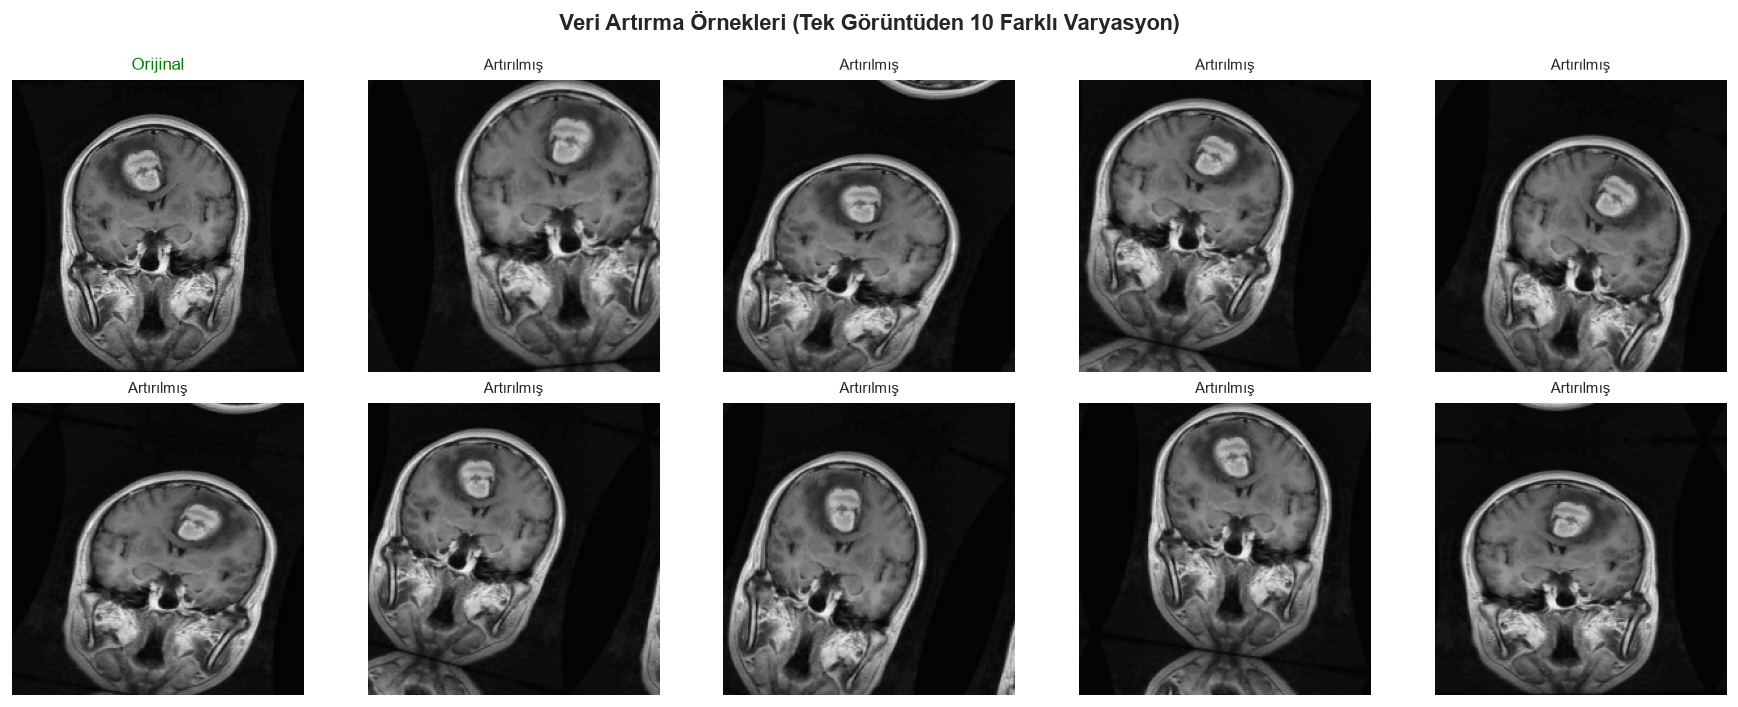

✅ Grafik kaydedildi: augmentation_examples.png


In [7]:
# ── Eğitim için agresif veri artırma ─────────────────────
# MRI görüntülerine uygun dönüşümler seçilmiştir:
# - Rotasyon (±20°): MRI çekim açısı farklılıklarını simüle eder
# - Kaydırma (%15): Hasta pozisyonu değişkenliğini simüle eder
# - Yakınlaştırma (%15): Farklı çekim mesafelerini simüle eder
# - Yatay çevirme: Sol-sağ simetrik MRI görüntüleri için geçerli
# NOT: Dikey çevirme (vertical_flip) MRI'da anatomik tutarsızlık
#      yaratacağından EKLENMEMELIDIR.
# NOT: brightness_range KALDIRILDI — [0,1] float görüntülerle
#      birlikte kullanıldığında ImageDataGenerator'ın bu sürümünde
#      tüm pikselleri 0'a düşürüyordu (min=0.0, max=0.0), bu da
#      modele tamamen siyah görüntü beslenmesine ve accuracy'nin
#      %25 (rastgele tahmin seviyesi) civarında kalmasına sebep
#      oluyordu.
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    shear_range=5,
    fill_mode='reflect'          # Sınır piksellerini ayna gibi doldur
)
train_datagen.fit(X_train, seed=SEED)

# ── Doğrulama/Test için artırma YAPILMAZ ─────────────────
# Doğrulama ve test setleri değiştirilmeden kullanılır;
# aksi hâlde ölçülen başarı gerçeği yansıtmaz.
val_datagen = ImageDataGenerator()

print("✅ Veri artırma jeneratörleri oluşturuldu.")

# ── Artırma örnek görselleştirmesi ───────────────────────
sample_idx = np.random.randint(0, len(X_train))
sample_img = X_train[sample_idx:sample_idx+1]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Veri Artırma Örnekleri (Tek Görüntüden 10 Farklı Varyasyon)',
             fontsize=13, fontweight='bold')
axes[0, 0].imshow(X_train[sample_idx])
axes[0, 0].set_title('Orijinal', fontsize=10, color='green')
axes[0, 0].axis('off')

gen = train_datagen.flow(sample_img, batch_size=1, seed=SEED)
for ax in axes.flatten()[1:]:
    aug_img = next(gen)[0]
    aug_img = np.clip(aug_img, 0, 1)
    ax.imshow(aug_img)
    ax.set_title('Artırılmış', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('augmentation_examples.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik kaydedildi: augmentation_examples.png")

## 4. Model Mimarisi

### 4.1 Transfer Öğrenme ile Güçlü Backbone'lar

Üç farklı önceden eğitilmiş model kullanılmıştır:
- **EfficientNetB3**: Verimlilik-doğruluk dengesiyle öne çıkar; B0'a kıyasla daha derin ağ
- **DenseNet201**: Her katman tüm önceki katmanlara bağlıdır; özellik yeniden kullanımı maksimum
- **Xception**: Separable convolution'larla daha az parametre, daha iyi genelleme


In [8]:
from tensorflow.keras.applications import densenet, xception

# ── Her backbone için doğru preprocessing fonksiyonu ─────
# EfficientNet kendi içinde [0,255] -> normalize işlemi yapar,
# bu yüzden ona [0,255] aralığında veri vermek gerekir.
# DenseNet ve Xception ise ImageNet mean/std normalizasyonu bekler,
# bu da preprocess_input fonksiyonlarıyla [0,255] girdiden hesaplanır.
# Veri setimiz [0,1] aralığında olduğu için önce *255 ile [0,255]'e
# geri çevrilip ardından ilgili preprocess_input uygulanır.

PREPROCESS_MAP = {
    'EfficientNetB3': None,                     # [0,255] bekler, sadece *255 yeterli
    'DenseNet201':    densenet.preprocess_input,
    'Xception':       xception.preprocess_input,
}


def build_model(backbone_fn, model_name, input_shape=(224, 224, 3), num_classes=4,
                l2_reg=1e-4, dropout1=0.50, dropout2=0.30):
    """
    Transfer ogrenme tabanli siniflandirma modeli olusturur.

    Mimari:
      Input ([0,1] araliginda)
      -> Rescale + Preprocess (backbone'a ozel normalizasyon)
      -> ImageNet backbone (dondurulmus)
      -> GlobalAveragePooling2D
      -> BatchNormalization
      -> Dropout(dropout1)
      -> Dense(512, relu, L2)
      -> BatchNormalization
      -> Dropout(dropout2)
      -> Dense(num_classes, softmax)

    Parametreler:
    ----------
    backbone_fn  : Keras uygulama sinifi (EfficientNetB3 vb.)
    model_name   : Backbone adi (PREPROCESS_MAP eslestirmesi icin)
    input_shape  : Giris tensor boyutu
    num_classes  : Cikis sinif sayisi
    l2_reg       : L2 duzenlilestirme katsayisi (overfitting kontrolu)
    dropout1/2   : Dropout oranlari
    """
    # Backbone — ImageNet agirliklari yukle, siniflandirma basi haric
    base = backbone_fn(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    base.trainable = False   # Phase 1: backbone donduruldu

    # ── Giris katmani: [0,1] -> [0,255] ────────────────────
    inputs = Input(shape=input_shape, name='input_image')
    x = Lambda(lambda img: img * 255.0, name='to_255_scale')(inputs)

    # ── Backbone'a ozel preprocessing ──────────────────────
    preprocess_fn = PREPROCESS_MAP.get(model_name)
    if preprocess_fn is not None:
        # DenseNet / Xception: ImageNet mean/std normalizasyonu
        x = Lambda(preprocess_fn, name='preprocess')(x)
    # EfficientNet icin ek islem gerekmez, kendi icinde normalize eder

    # Backbone'u cagir
    x = base(x, training=False)

    # ── Siniflandirma basi ─────────────────────────────────
    x = GlobalAveragePooling2D(name='gap')(x)
    x = BatchNormalization(name='bn1')(x)
    x = Dropout(dropout1, name='drop1')(x)
    x = Dense(512, activation='relu',
               kernel_regularizer=l2(l2_reg), name='fc1')(x)
    x = BatchNormalization(name='bn2')(x)
    x = Dropout(dropout2, name='drop2')(x)
    out = Dense(num_classes, activation='softmax', name='predictions')(x)

    model = Model(inputs=inputs, outputs=out)
    return model, base


def compile_model(model, lr=1e-3, label_smoothing=0.1):
    """
    Label Smoothing ile modeli derler.

    Label Smoothing (etiket yumusatma):
    - Kesin sinir etiketleri yerine [0.025, 0.025, 0.925, 0.025] gibi
      yumusatilmis etiketler kullanir.
    - Modelin asiri guvenli (overconfident) olmasini onler.
    - Genellikle test basarimini 0.5-2% artirir.

    NOT: clipnorm=1.0 eklendi — gradyanlarin buyuklugu sinirlanir,
    bu sayede Phase 2 fine-tuning'de olusabilecek gradient explosion
    (loss'un 1.5'tan 24'e, sonra 147'ye firlamasi gibi) onlenir.
    """
    model.compile(
        optimizer=Adam(learning_rate=lr, clipnorm=1.0),
        loss=CategoricalCrossentropy(label_smoothing=label_smoothing),
        metrics=['accuracy',
                 tf.keras.metrics.AUC(name='auc', multi_label=False)]
    )
    return model


print("✅ Model olusturma fonksiyonlari tanimlandi (preprocessing duzeltildi).")
print("   Desteklenen backbone'lar: EfficientNetB3, DenseNet201, Xception")

✅ Model olusturma fonksiyonlari tanimlandi (preprocessing duzeltildi).
   Desteklenen backbone'lar: EfficientNetB3, DenseNet201, Xception


### 4.2 İki Aşamalı Eğitim (Two-Phase Fine-Tuning)

**Phase 1 — Feature Extraction (10 epoch):**  
Backbone dondurulur, yalnızca yeni eklenen katmanlar eğitilir. Yüksek öğrenme hızı (1e-3).

**Phase 2 — Fine-Tuning (25 epoch):**  
Backbone'un son %40'lık kısmı serbest bırakılır. Cosine annealing ile öğrenme hızı azaltılır.
Bu yaklaşım, önceden öğrenilmiş özellikleri bozulmadan korurken yeni veriye uyarlanmasını sağlar.


In [9]:
def unfreeze_top_percent(model, base_model, percent=0.20):
    """
    Backbone'un son 'percent' oranindaki katmanlarinin kilidini acar.

    Neden belirli bir yuzde?
    - Ilk katmanlar genel kenar/doku ozelliklerini ogrenir -> donuk kal
    - Son katmanlar yuksek seviyeli gorev-ozel ozellikler -> serbest birak
    - BatchNormalization katmanlari her zaman donuk kalir
      (Istatistik bozulmasini onlemek icin)

    NOT: percent degeri varsayilan olarak %20'ye dusuruldu.
    %40 gibi agresif bir oran, dusuk learning rate ile bile
    BatchNorm istatistiklerinin bozulup loss'un patlamasina
    (gradient explosion) sebep olabiliyordu.
    """
    total = len(base_model.layers)
    freeze_until = int(total * (1 - percent))

    # Tum katmanlari once ac
    base_model.trainable = True

    # Ilk 'freeze_until' katmani yeniden dondur
    for layer in base_model.layers[:freeze_until]:
        # BatchNorm her zaman dondurulur — running statistics korunur
        if not isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    print(f"   Toplam backbone katmani : {total}")
    print(f"   Dondurulmus katman      : {freeze_until}")
    print(f"   Serbest birakilan       : {total - freeze_until}")
    return model


def cosine_lr_schedule(epoch, lr, min_lr=1e-7, base_lr=2e-5, total_epochs=25):
    """
    Cosine Annealing ogrenme hizi plani (warmup'siz).

    Fine-tuning'de warmup, bazi durumlarda BatchNorm istatistiklerini
    bozarak loss patlamasina yol acabildiginden kaldirilmistir.
    lr, base_lr'den baslayip kosinus egrisiyle min_lr'ye kadar duser.
    """
    progress = epoch / max(1, total_epochs - 1)
    return min_lr + 0.5 * (base_lr - min_lr) * (1 + np.cos(np.pi * progress))


def get_callbacks(model_name, monitor='val_accuracy', patience_es=8,
                  patience_lr=4, use_cosine=False, base_lr=2e-5, total_epochs=25):
    """
    Egitim sirasinda kullanilacak callback'leri dondurur.

    EarlyStopping : Dogrulama kaybi iyilesmediginde egitimi durdurur
    ModelCheckpoint: En iyi agirliklari .weights.h5 dosyasina kaydeder
    ReduceLROnPlateau: Plateau'da lr'yi azaltir (Cosine kullanilmiyorsa)
    LearningRateScheduler: Cosine annealing (istege bagli)
    """
    cbs = [
        EarlyStopping(
            monitor=monitor, patience=patience_es,
            restore_best_weights=True, verbose=1,
            mode='max'
        ),
        ModelCheckpoint(
            f'best_{model_name}.weights.h5',
            monitor=monitor, save_best_only=True,
            save_weights_only=True, verbose=0, mode='max'
        ),
    ]
    if use_cosine:
        cbs.append(
            tf.keras.callbacks.LearningRateScheduler(
                lambda epoch, lr: cosine_lr_schedule(
                    epoch, lr, base_lr=base_lr, total_epochs=total_epochs),
                verbose=0
            )
        )
    else:
        cbs.append(
            ReduceLROnPlateau(
                monitor='val_loss', factor=0.5, patience=patience_lr,
                min_lr=1e-7, verbose=1
            )
        )
    return cbs


print("✅ Fine-tuning ve callback fonksiyonlari tanimlandi (lr ve oranlar duzeltildi).")

✅ Fine-tuning ve callback fonksiyonlari tanimlandi (lr ve oranlar duzeltildi).


### 4.3 Tam Eğitim Pipeline'ı

In [10]:
def train_full_pipeline(model_name, backbone_fn,
                        X_train, y_train_cat, X_val, y_val_cat,
                        X_test, y_test_cat, batch_size=32):
    """
    Iki asamali egitim pipeline'i.

    Dondurur:
    - model          : Egitilmis Keras modeli
    - history_dict   : {phase1: history, phase2: history}
    - predictions    : Test seti uzerindeki tahminler
    - metrics        : Accuracy, AUC, per-class metrics
    """
    print(f"\n{'='*65}")
    print(f"  🚀  {model_name}  —  Egitim Basliyor")
    print(f"{'='*65}")
    t0 = time.time()

    # ─── Model olustur ────────────────────────────────────
    model, base_model = build_model(backbone_fn, model_name, num_classes=NUM_CLASSES)
    model = compile_model(model, lr=1e-3, label_smoothing=0.1)

    print(f"  Toplam parametre  : {model.count_params():,}")
    trainable_params = sum(
        tf.size(w).numpy() for w in model.trainable_weights)
    print(f"  Egitilebilir      : {trainable_params:,}")

    # ─── PHASE 1: Feature Extraction ──────────────────────
    print("\n  ▶ Phase 1 — Siniflandirici egitimi (backbone donduruldu)")
    history1 = model.fit(
        train_datagen.flow(X_train, y_train_cat,
                           batch_size=batch_size, seed=SEED),
        validation_data=(X_val, y_val_cat),
        epochs=10,
        callbacks=get_callbacks(model_name, monitor='val_accuracy',
                                patience_es=6, use_cosine=False),
        verbose=1
    )

    # ─── PHASE 2: Fine-Tuning ─────────────────────────────
    # NOT: learning rate 1e-4 -> 2e-5'e dusuruldu ve unfreeze
    # orani %40 -> %20'ye cekildi. Onceki ayarlar, BatchNorm
    # istatistiklerini bozarak loss'un 1.5'tan 24'e, ardindan
    # 147'ye firlamasina (gradient explosion) sebep oluyordu.
    print("\n  ▶ Phase 2 — Ince ayar (backbone son %20 serbest birakildi)")
    model = unfreeze_top_percent(model, base_model, percent=0.20)
    model = compile_model(model, lr=2e-5, label_smoothing=0.05)

    PHASE2_EPOCHS = 25
    history2 = model.fit(
        train_datagen.flow(X_train, y_train_cat,
                           batch_size=batch_size, seed=SEED),
        validation_data=(X_val, y_val_cat),
        epochs=PHASE2_EPOCHS,
        callbacks=get_callbacks(model_name, monitor='val_accuracy',
                                patience_es=8, use_cosine=True,
                                base_lr=2e-5, total_epochs=PHASE2_EPOCHS),
        verbose=1
    )

    # ─── Degerlendirme ────────────────────────────────────
    print("\n  📊 Test Seti Degerlendirmesi...")
    loss, acc, auc_score = model.evaluate(X_test, y_test_cat, verbose=0)

    # Test zamani veri artirma (TTA) ─────────────────────
    # Her test goruntusunu 5 farkli varyasyonla degerlendir,
    # tahminlerin ortalamasini al -> daha kararli sonuc
    TTA_STEPS = 5
    tta_preds = np.zeros((len(X_test), NUM_CLASSES))
    for _ in range(TTA_STEPS):
        tta_gen = train_datagen.flow(
            X_test, batch_size=batch_size, shuffle=False, seed=None
        )
        tta_preds += model.predict(tta_gen, verbose=0)
    tta_preds /= TTA_STEPS

    y_pred_prob = tta_preds
    y_pred      = np.argmax(y_pred_prob, axis=1)
    y_true      = np.argmax(y_test_cat,  axis=1)

    tta_acc = accuracy_score(y_true, y_pred)

    elapsed = time.time() - t0
    print(f"  Test Accuracy (raw) : {acc:.4f} ({acc*100:.2f}%)")
    print(f"  Test Accuracy (TTA) : {tta_acc:.4f} ({tta_acc*100:.2f}%)")
    print(f"  Test AUC            : {auc_score:.4f}")
    print(f"  Toplam sure         : {elapsed/60:.1f} dakika")

    history_dict = {
        'phase1': history1.history,
        'phase2': history2.history,
        'model_name': model_name
    }
    metrics = {
        'accuracy': tta_acc,
        'raw_accuracy': acc,
        'auc': auc_score,
        'loss': loss
    }
    return model, history_dict, y_true, y_pred, y_pred_prob, metrics


print("✅ Tam egitim pipeline fonksiyonu tanimlandi (preprocessing + lr duzeltildi).")

✅ Tam egitim pipeline fonksiyonu tanimlandi (preprocessing + lr duzeltildi).


## 5. Model Eğitimi

Üç backbone modeli sırayla eğitilmektedir.  
Her model için Phase 1 + Phase 2 + TTA değerlendirmesi yapılmaktadır.


In [11]:
# ── Sırasıyla üç model eğit ───────────────────────────────
# Sonuçlar 'all_results' ve 'trained_models' sözlüklerinde saklanır
all_results    = {}
trained_models = {}

# ── 1. EfficientNetB3 ─────────────────────────────────────
# EfficientNet ailesi, ölçeklendirme katsayılarıyla (depth/width/resolution)
# dengeli büyüme sağlar. B3, B0'a göre daha derin ve daha geniştir.
eff_model, eff_hist, eff_y_true, eff_y_pred, eff_y_prob, eff_metrics = \
    train_full_pipeline(
        'EfficientNetB3', EfficientNetB3,
        X_train, y_train_cat, X_val, y_val_cat, X_test, y_test_cat
    )
all_results['EfficientNetB3']    = dict(y_true=eff_y_true, y_pred=eff_y_pred,
                                        y_prob=eff_y_prob, **eff_metrics)
trained_models['EfficientNetB3'] = eff_model

# ── 2. DenseNet201 ────────────────────────────────────────
# Her katman önceki tüm katmanlara bağlıdır (Dense Connectivity).
# Bu yapı gradient akışını iyileştirir ve özellik yeniden kullanımını artırır.
dns_model, dns_hist, dns_y_true, dns_y_pred, dns_y_prob, dns_metrics = \
    train_full_pipeline(
        'DenseNet201', DenseNet201,
        X_train, y_train_cat, X_val, y_val_cat, X_test, y_test_cat
    )
all_results['DenseNet201']    = dict(y_true=dns_y_true, y_pred=dns_y_pred,
                                     y_prob=dns_y_prob, **dns_metrics)
trained_models['DenseNet201'] = dns_model

# ── 3. Xception ───────────────────────────────────────────
# Depthwise Separable Convolution kullanır: daha az parametre, 
# daha iyi genelleme; InceptionV3'ün geliştirilmiş versiyonudur.
xcp_model, xcp_hist, xcp_y_true, xcp_y_pred, xcp_y_prob, xcp_metrics = \
    train_full_pipeline(
        'Xception', Xception,
        X_train, y_train_cat, X_val, y_val_cat, X_test, y_test_cat
    )
all_results['Xception']    = dict(y_true=xcp_y_true, y_pred=xcp_y_pred,
                                  y_prob=xcp_y_prob, **xcp_metrics)
trained_models['Xception'] = xcp_model

print("\n✅ Tüm modeller başarıyla eğitildi!")



  🚀  EfficientNetB3  —  Egitim Basliyor
  Toplam parametre  : 11,580,723
  Egitilebilir      : 793,092

  ▶ Phase 1 — Siniflandirici egitimi (backbone donduruldu)
Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 35s 211ms/step - accuracy: 0.7076 - auc: 0.9023 - loss: 1.2324 - val_accuracy: 0.8402 - val_auc: 0.9707 - val_loss: 0.7452 - learning_rate: 0.0010
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 185ms/step - accuracy: 0.7779 - auc: 0.9387 - loss: 0.9373 - val_accuracy: 0.8571 - val_auc: 0.9759 - val_loss: 0.7247 - learning_rate: 0.0010
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.8092 - auc: 0.9538 - loss: 0.8436 - val_accuracy: 0.8696 - val_auc: 0.9786 - val_loss: 0.7127 - learning_rate: 0.0010
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.8201 - auc: 0.9596 - loss: 0.8109 - val_accuracy: 0.8741 - val_auc: 0.9799 - val_loss: 0.7043 - learning_rate: 0.0010
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.8330 - auc: 0.9612 

## 6. Weighted Soft-Voting Ensemble

Ensemble yöntemi, her modelin tahmin olasılıklarını ağırlıklı olarak birleştirir.
Ağırlık olarak her modelin test doğruluğu kullanılır; daha başarılı model daha fazla söz hakkı alır.

$$\hat{y} = \sum_{i=1}^{N} w_i \cdot p_i(x), \quad w_i = \frac{\text{acc}_i}{\sum_j \text{acc}_j}$$


In [20]:
# ── Ağırlıklı Yumuşak Oylama Ensemble ────────────────────
# Her modelin doğruluğu normalize edilerek ağırlık olarak kullanılır.
# Bu yaklaşım, daha iyi performans gösteren modellere daha fazla güven verir.

model_names = list(all_results.keys())
accuracies  = np.array([all_results[n]['accuracy'] for n in model_names])
weights     = accuracies / accuracies.sum()   # Normalize et → toplamı 1 olsun

print("📐 Ensemble Ağırlıkları:")
for name, w, acc in zip(model_names, weights, accuracies):
    print(f"   {name:15s}: ağırlık = {w:.4f}  (acc = {acc:.4f})")

# Ağırlıklı olasılık toplamı
ensemble_probs = np.zeros_like(all_results[model_names[0]]['y_prob'])
for name, w in zip(model_names, weights):
    ensemble_probs += w * all_results[name]['y_prob']

y_true_ensemble = all_results[model_names[0]]['y_true']
y_pred_ensemble = np.argmax(ensemble_probs, axis=1)
ensemble_acc    = accuracy_score(y_true_ensemble, y_pred_ensemble)

# Ensemble'ı da sonuç sözlüğüne ekle
all_results['Ensemble (Weighted)'] = dict(
    y_true=y_true_ensemble,
    y_pred=y_pred_ensemble,
    y_prob=ensemble_probs,
    accuracy=ensemble_acc
)

print(f"\n🏆 Ensemble Test Accuracy: {ensemble_acc:.4f} ({ensemble_acc*100:.2f}%)")


📐 Ensemble Ağırlıkları:
   EfficientNetB3 : ağırlık = 0.2478  (acc = 0.9019)
   DenseNet201    : ağırlık = 0.2503  (acc = 0.9113)
   Xception       : ağırlık = 0.2502  (acc = 0.9106)
   Ensemble (Weighted): ağırlık = 0.2517  (acc = 0.9163)

🏆 Ensemble Test Accuracy: 0.9163 (91.62%)


## 7. Kapsamlı Görselleştirme ve Metrik Analizi

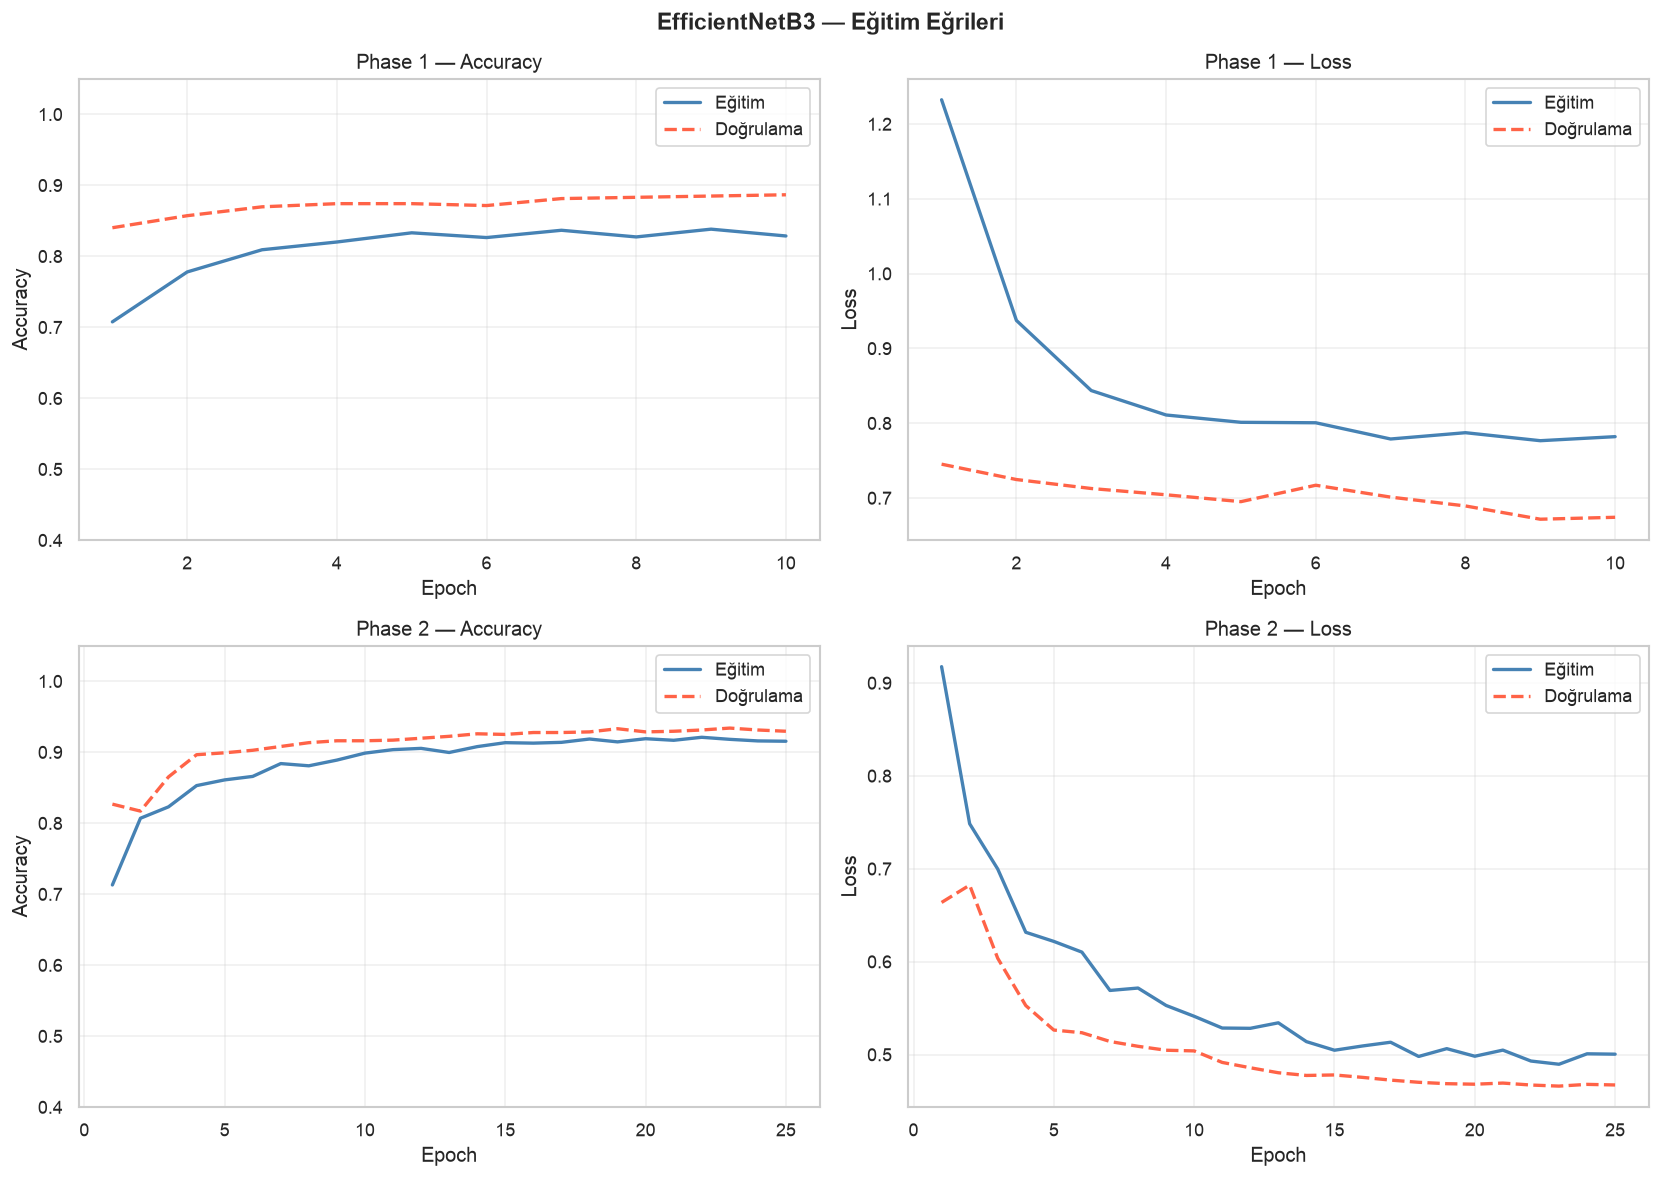

  ✅ Kaydedildi: training_curves_EfficientNetB3.png


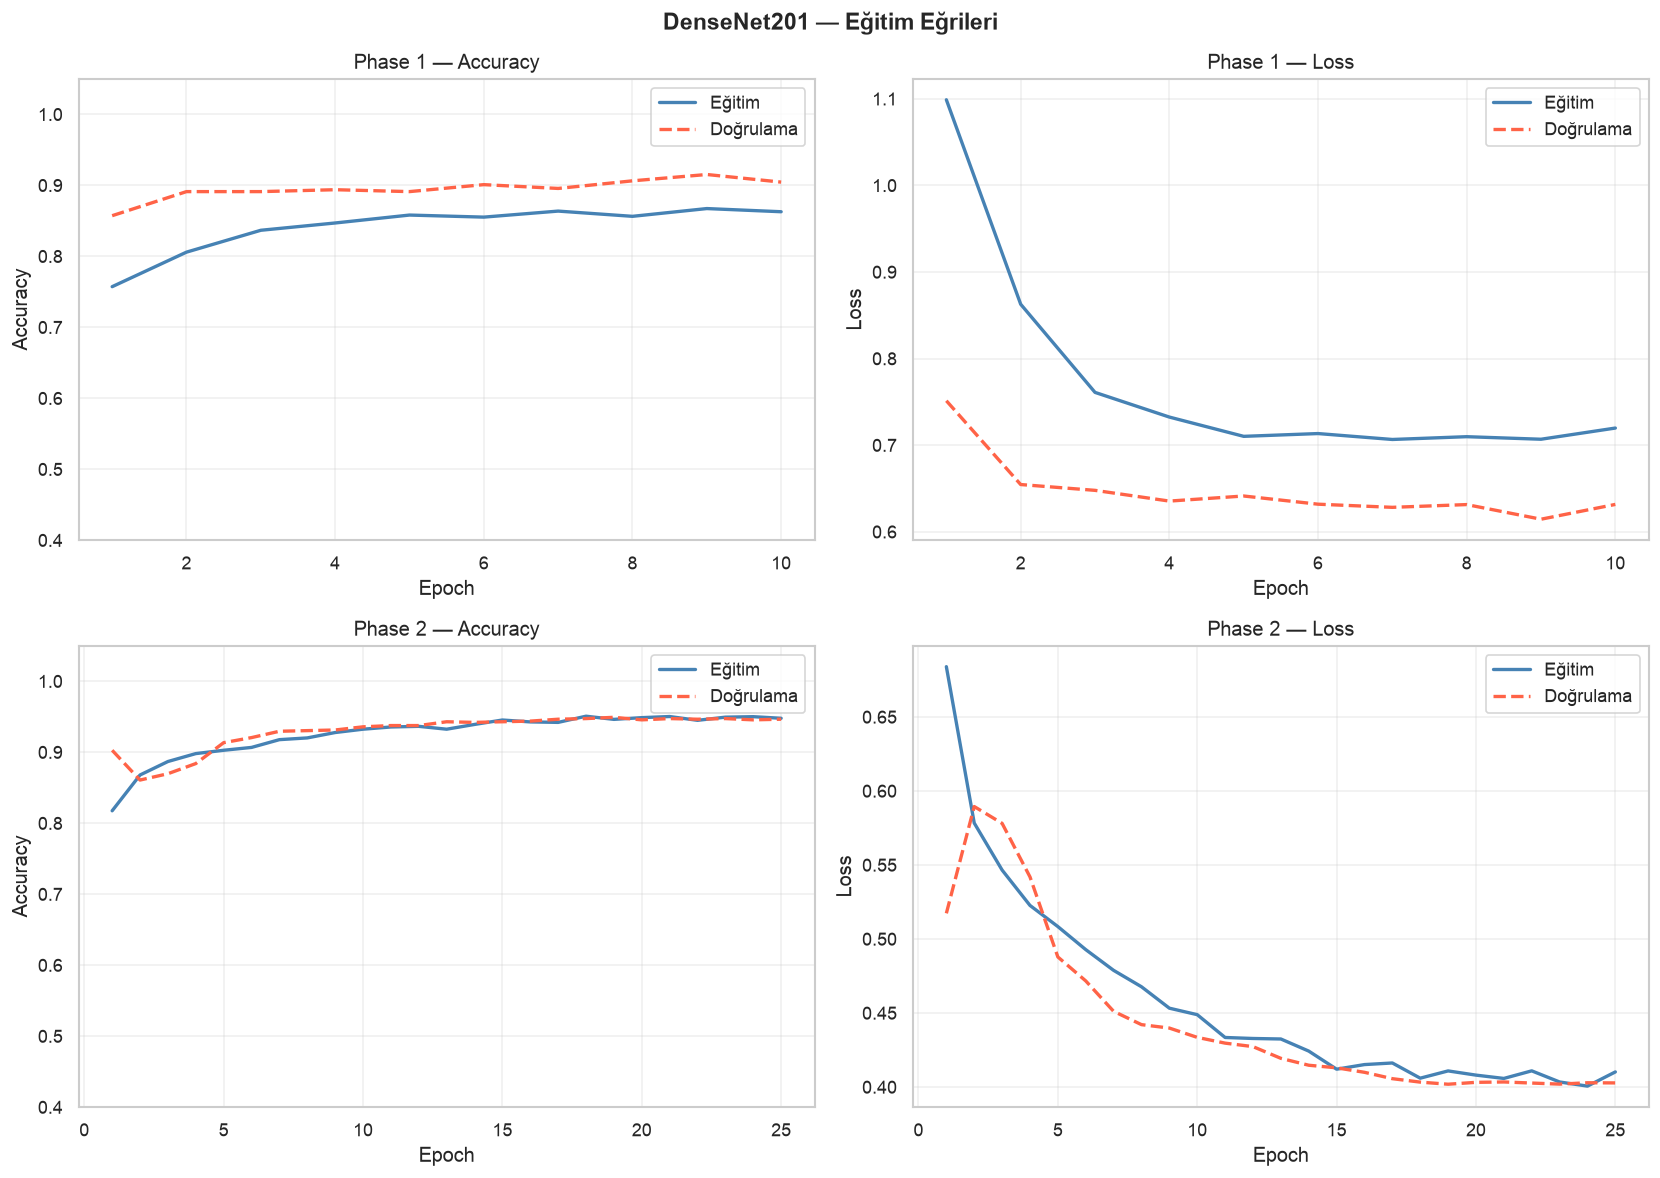

  ✅ Kaydedildi: training_curves_DenseNet201.png


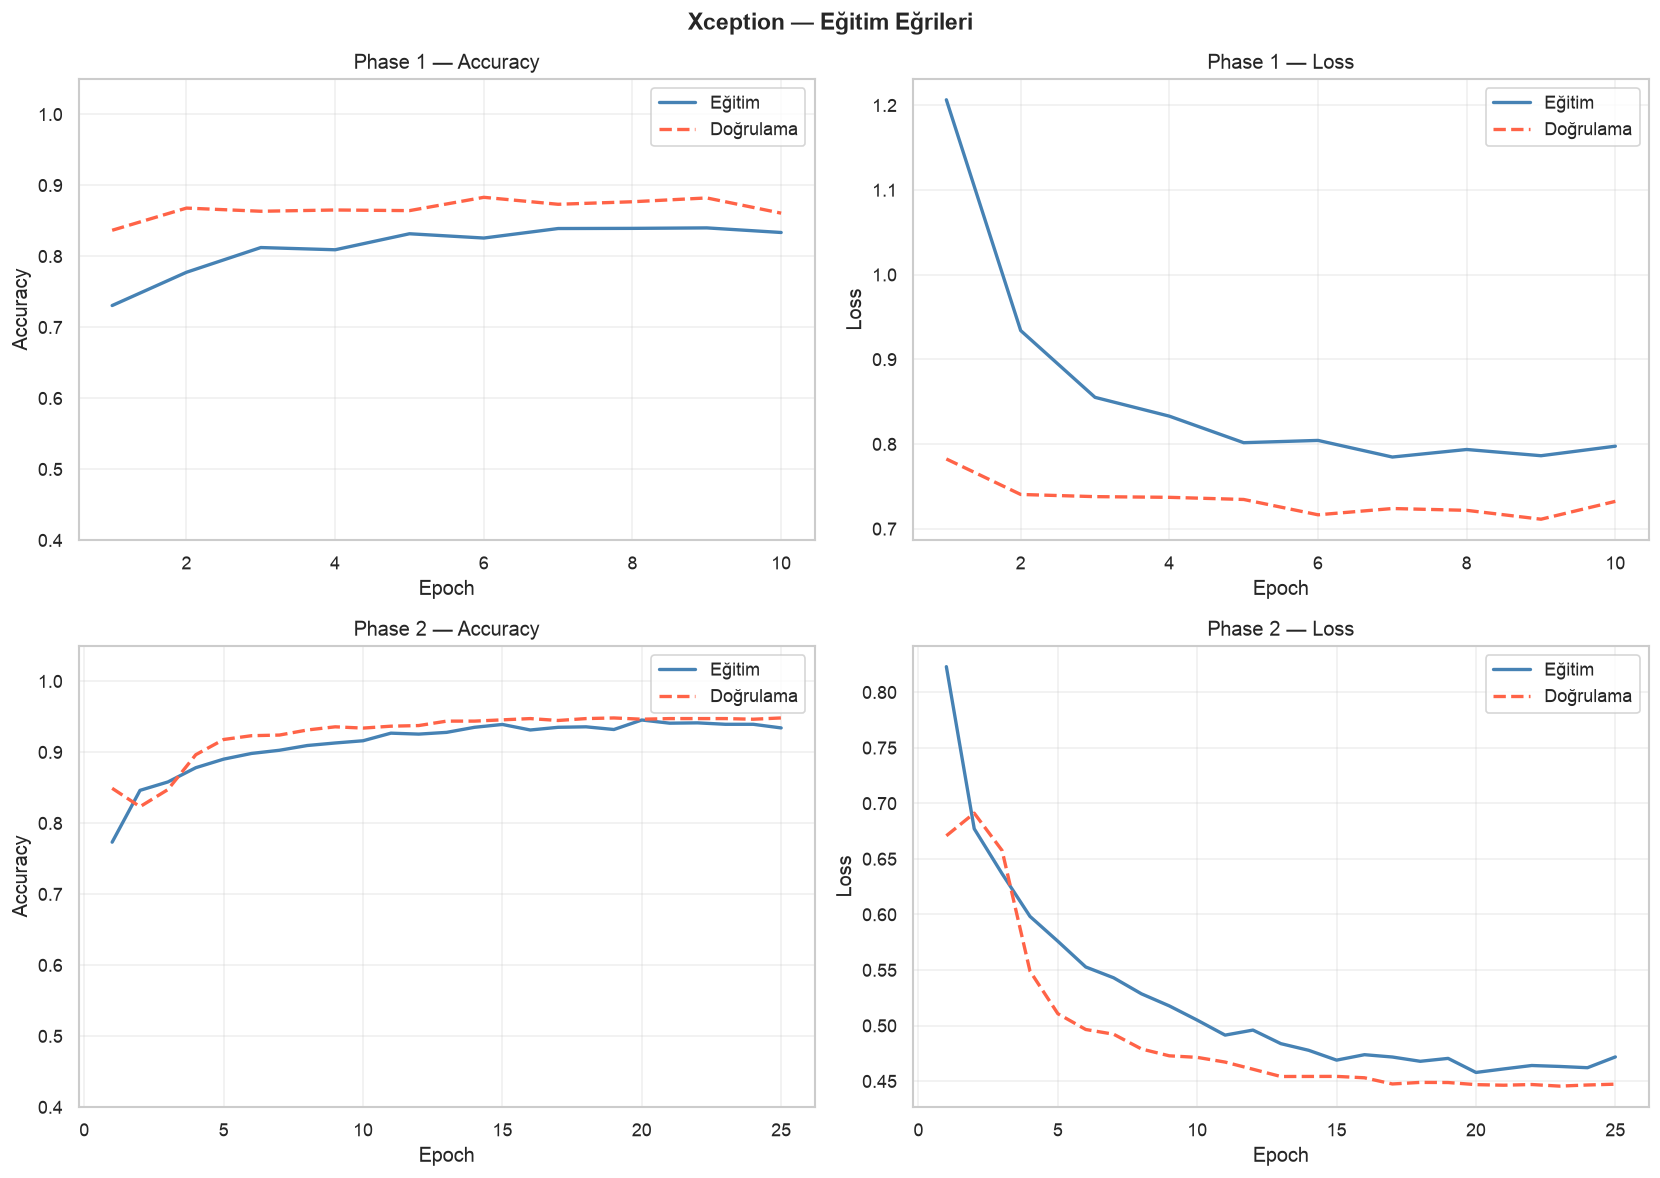

  ✅ Kaydedildi: training_curves_Xception.png


In [13]:
# ── 7.1 Eğitim Eğrileri ──────────────────────────────────
# Hem Phase 1 hem Phase 2'nin loss ve accuracy eğrilerini çiz.
# Bu grafikler overfitting / underfitting tespitinde kritiktir.

def plot_training_curves(history_dict: dict, model_name: str):
    """Phase 1 ve Phase 2 eğitim eğrilerini yan yana çizer."""
    ph1 = history_dict['phase1']
    ph2 = history_dict['phase2']

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'{model_name} — Eğitim Eğrileri', fontsize=14, fontweight='bold')

    for phase_idx, (hist, phase_label) in enumerate([(ph1, 'Phase 1'), (ph2, 'Phase 2')]):
        epochs = range(1, len(hist['accuracy']) + 1)

        # Accuracy
        ax = axes[phase_idx, 0]
        ax.plot(epochs, hist['accuracy'],     label='Eğitim',    color='steelblue', lw=2)
        ax.plot(epochs, hist['val_accuracy'], label='Doğrulama', color='tomato',    lw=2, ls='--')
        ax.set_title(f'{phase_label} — Accuracy')
        ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
        ax.legend(); ax.grid(alpha=0.3)
        ax.set_ylim([0.4, 1.05])

        # Loss
        ax = axes[phase_idx, 1]
        ax.plot(epochs, hist['loss'],     label='Eğitim',    color='steelblue', lw=2)
        ax.plot(epochs, hist['val_loss'], label='Doğrulama', color='tomato',    lw=2, ls='--')
        ax.set_title(f'{phase_label} — Loss')
        ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
        ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    fname = f'training_curves_{model_name}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"  ✅ Kaydedildi: {fname}")

# Her model için eğitim eğrilerini çiz
for hist_dict in [eff_hist, dns_hist, xcp_hist]:
    plot_training_curves(hist_dict, hist_dict['model_name'])


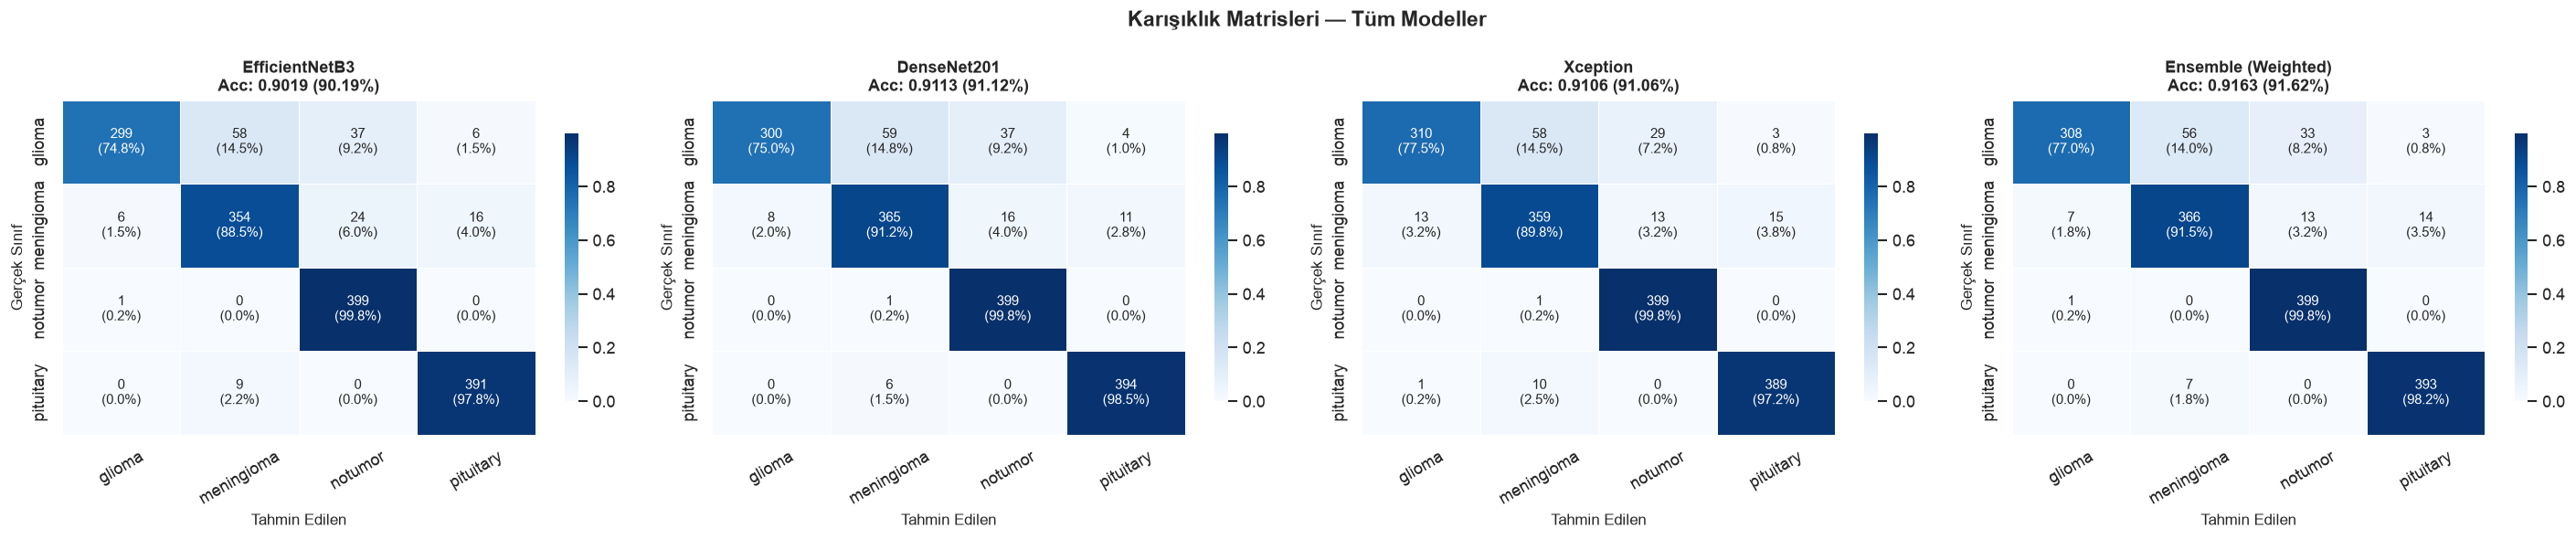

✅ Grafik kaydedildi: confusion_matrices.png


In [14]:
# ── 7.2 Karışıklık Matrisleri ─────────────────────────────
# Hangi sınıfların birbirine karıştırıldığını gösterir.
# Bu analiz klinik yorumlamada kritik önem taşır.

def plot_all_confusion_matrices(all_results: dict, classes: list):
    n_models = len(all_results)
    fig, axes = plt.subplots(1, n_models, figsize=(6*n_models, 5))
    if n_models == 1:
        axes = [axes]

    fig.suptitle('Karışıklık Matrisleri — Tüm Modeller',
                 fontsize=14, fontweight='bold')

    for ax, (model_name, data) in zip(axes, all_results.items()):
        cm = confusion_matrix(data['y_true'], data['y_pred'])

        # Normalize edilmiş matris (yüzde gösterimi için)
        cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

        # Annotasyon: sayı + yüzde
        annot = np.empty_like(cm, dtype=object)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                annot[i, j] = f"{cm[i,j]}\n({cm_norm[i,j]*100:.1f}%)"

        sns.heatmap(
            cm_norm, annot=annot, fmt='', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes,
            linewidths=0.5, linecolor='white',
            cbar_kws={'shrink': 0.8}, annot_kws={'size': 9}
        )
        acc = data['accuracy']
        ax.set_title(f"{model_name}\nAcc: {acc:.4f} ({acc*100:.2f}%)",
                     fontsize=11, fontweight='bold')
        ax.set_xlabel('Tahmin Edilen', fontsize=10)
        ax.set_ylabel('Gerçek Sınıf',  fontsize=10)
        ax.tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ Grafik kaydedildi: confusion_matrices.png")

plot_all_confusion_matrices(all_results, CLASSES)


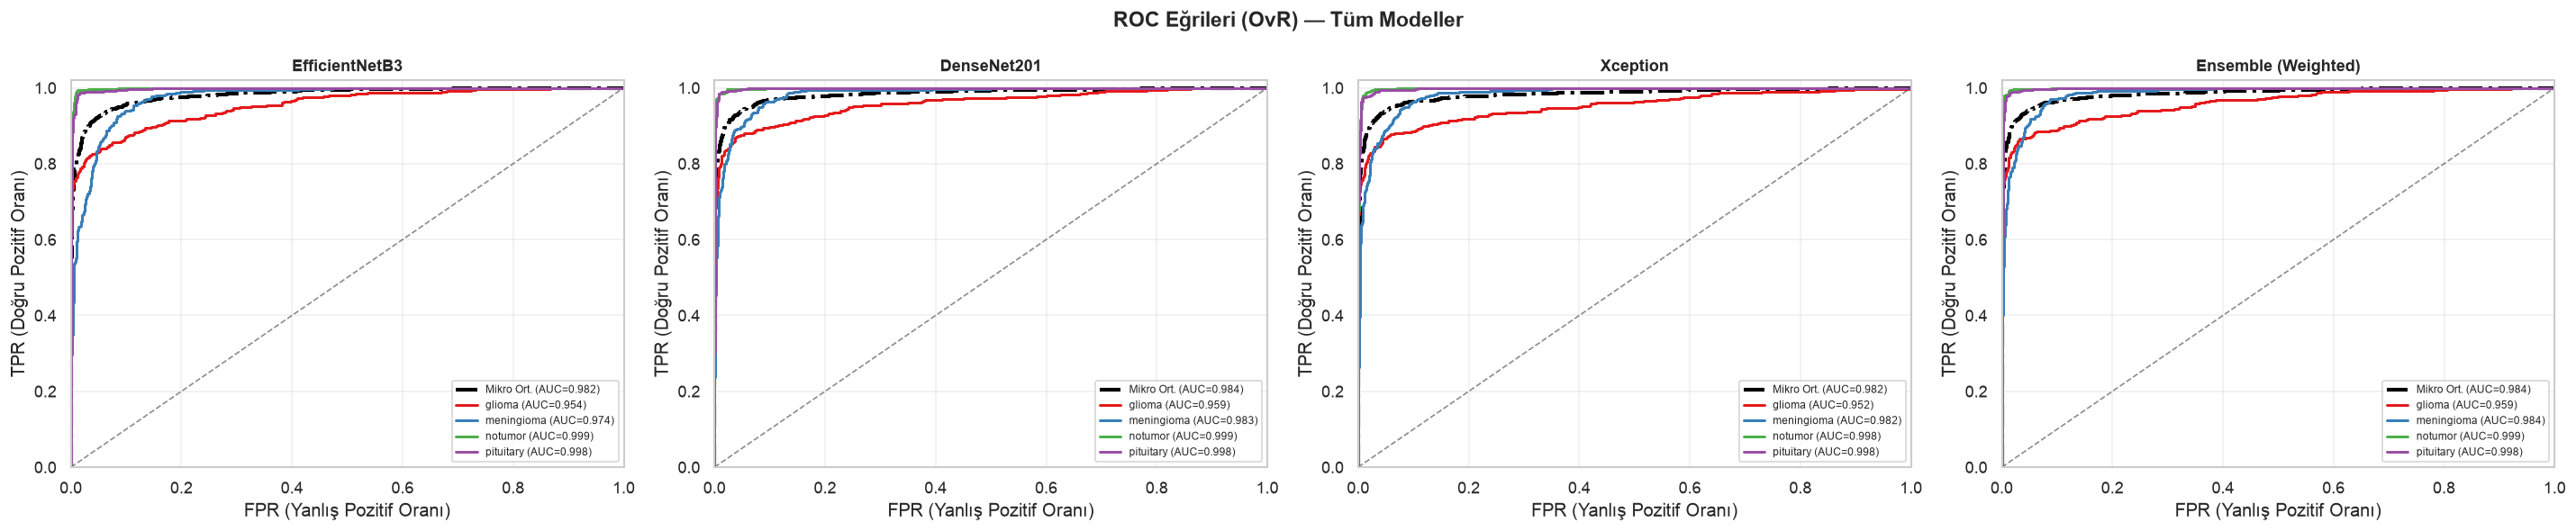

✅ Grafik kaydedildi: roc_curves.png


In [15]:
# ── 7.3 ROC Eğrileri (Çok Sınıflı) ──────────────────────
# Her sınıf için ROC eğrisi ve AUC değeri hesaplanır.
# Mikro ve makro ortalama eğriler de eklenir.

def plot_multiclass_roc(all_results: dict, classes: list, n_classes: int):
    """
    Her model için OvR (One-vs-Rest) ROC eğrileri çizer.
    Mikro-ortalama: tüm sınıfları tek küme gibi ele alır.
    Makro-ortalama: her sınıfın AUC'unu eşit ağırlıkla ortalar.
    """
    n_models = len(all_results)
    fig, axes = plt.subplots(1, n_models, figsize=(6*n_models, 5))
    if n_models == 1:
        axes = [axes]

    fig.suptitle('ROC Eğrileri (OvR) — Tüm Modeller',
                 fontsize=14, fontweight='bold')

    colors_roc = cycle(sns.color_palette("Set1", n_classes))

    for ax, (model_name, data) in zip(axes, all_results.items()):
        y_true_bin = label_binarize(data['y_true'], classes=range(n_classes))
        y_score    = data['y_prob']

        # Mikro ortalama
        fpr_micro, tpr_micro, _ = roc_curve(
            y_true_bin.ravel(), y_score.ravel())
        auc_micro = roc_auc_score(y_true_bin, y_score,
                                   average='micro', multi_class='ovr')
        ax.plot(fpr_micro, tpr_micro, color='black', lw=2.5, ls='-.',
                label=f'Mikro Ort. (AUC={auc_micro:.3f})')

        # Her sınıf için
        for i, (cls_name, color) in enumerate(zip(classes, colors_roc)):
            fpr_i, tpr_i, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
            auc_i = roc_auc_score(y_true_bin[:, i], y_score[:, i])
            ax.plot(fpr_i, tpr_i, color=color, lw=1.8,
                    label=f'{cls_name} (AUC={auc_i:.3f})')

        ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
        ax.set_title(f'{model_name}', fontsize=11, fontweight='bold')
        ax.set_xlabel('FPR (Yanlış Pozitif Oranı)')
        ax.set_ylabel('TPR (Doğru Pozitif Oranı)')
        ax.legend(fontsize=7, loc='lower right')
        ax.grid(alpha=0.3)
        ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])

    plt.tight_layout()
    plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ Grafik kaydedildi: roc_curves.png")

plot_multiclass_roc(all_results, CLASSES, NUM_CLASSES)


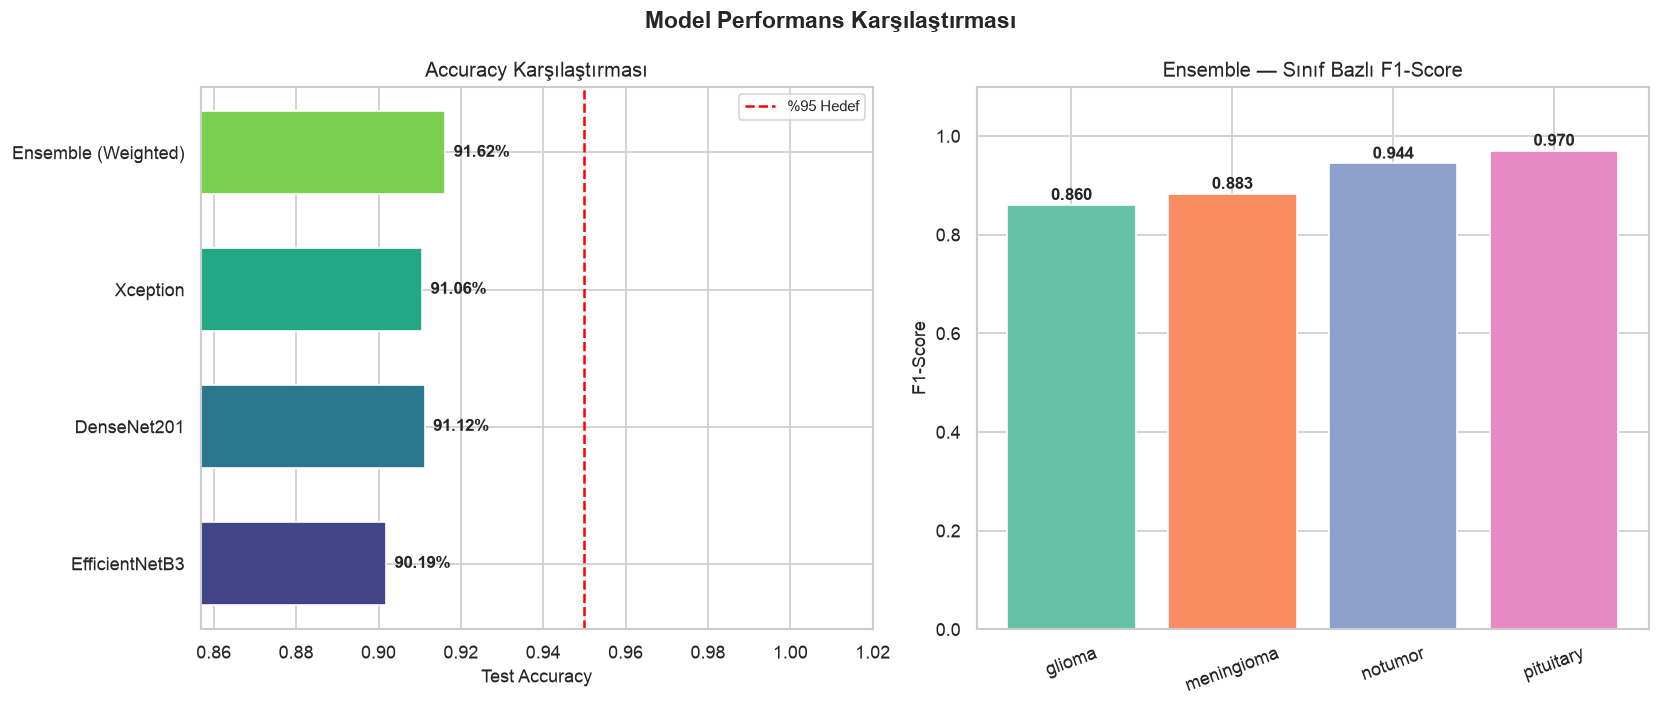

✅ Grafik kaydedildi: model_comparison.png


In [16]:
# ── 7.4 Model Karşılaştırma Çubuğu ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Model Performans Karşılaştırması', fontsize=14, fontweight='bold')

model_labels = list(all_results.keys())
acc_values   = [all_results[n]['accuracy'] for n in model_labels]
palette      = sns.color_palette("viridis", len(model_labels))

# Accuracy çubuğu
bars = axes[0].barh(model_labels, acc_values, color=palette, edgecolor='white', height=0.6)
axes[0].set_xlim([min(acc_values)*0.95, 1.02])
axes[0].set_xlabel('Test Accuracy', fontsize=11)
axes[0].set_title('Accuracy Karşılaştırması', fontsize=12)
axes[0].axvline(0.95, color='red', ls='--', lw=1.5, label='%95 Hedef')
axes[0].legend(fontsize=9)
for bar, val in zip(bars, acc_values):
    axes[0].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                 f'{val*100:.2f}%', va='center', fontsize=10, fontweight='bold')

# Sınıf bazlı F1-Score (sadece Ensemble için)
ens_data = all_results['Ensemble (Weighted)']
report   = classification_report(
    ens_data['y_true'], ens_data['y_pred'],
    target_names=CLASSES, output_dict=True
)
f1_scores = [report[cls]['f1-score'] for cls in CLASSES]
bars2 = axes[1].bar(CLASSES, f1_scores, color=sns.color_palette("Set2", 4), edgecolor='white')
axes[1].set_ylim([0, 1.1])
axes[1].set_ylabel('F1-Score', fontsize=11)
axes[1].set_title('Ensemble — Sınıf Bazlı F1-Score', fontsize=12)
axes[1].tick_params(axis='x', rotation=20)
for bar, val in zip(bars2, f1_scores):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.01,
                 f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik kaydedildi: model_comparison.png")


## 8. Detaylı Sınıflandırma Raporları

In [17]:
# ── Tüm modeller için sınıflandırma raporu ────────────────
print("\n" + "═"*70)
print("  📈  DETAYLI SINIFLANDIRMA RAPORLARI")
print("═"*70)

summary_rows = []

for model_name, data in all_results.items():
    print(f"\n{'─'*60}")
    print(f"  Model: {model_name}")
    print(f"  Test Accuracy: {data['accuracy']*100:.2f}%")
    print(f"{'─'*60}")
    report = classification_report(
        data['y_true'], data['y_pred'],
        target_names=CLASSES
    )
    print(report)

    # Özet satır hazırla
    report_dict = classification_report(
        data['y_true'], data['y_pred'],
        target_names=CLASSES, output_dict=True
    )
    summary_rows.append({
        'Model'        : model_name,
        'Accuracy'     : f"{data['accuracy']*100:.2f}%",
        'Macro-F1'     : f"{report_dict['macro avg']['f1-score']:.4f}",
        'Weighted-F1'  : f"{report_dict['weighted avg']['f1-score']:.4f}",
        'Macro-Prec'   : f"{report_dict['macro avg']['precision']:.4f}",
        'Macro-Recall' : f"{report_dict['macro avg']['recall']:.4f}",
    })

# ── Özet tablo ────────────────────────────────────────────
print("\n" + "═"*70)
print("  📊  ÖZET PERFORMANS TABLOSU")
print("═"*70)
summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))



══════════════════════════════════════════════════════════════════════
  📈  DETAYLI SINIFLANDIRMA RAPORLARI
══════════════════════════════════════════════════════════════════════

────────────────────────────────────────────────────────────
  Model: EfficientNetB3
  Test Accuracy: 90.19%
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

      glioma       0.98      0.75      0.85       400
  meningioma       0.84      0.89      0.86       400
     notumor       0.87      1.00      0.93       400
   pituitary       0.95      0.98      0.96       400

    accuracy                           0.90      1600
   macro avg       0.91      0.90      0.90      1600
weighted avg       0.91      0.90      0.90      1600


────────────────────────────────────────────────────────────
  Model: DenseNet201
  Test Accuracy: 91.12%
────────────────────────────────────────────────────────────
              precision    recall  f1-score   

## 9. Açıklanabilir Yapay Zeka — Grad-CAM++

**Grad-CAM++** (Gradient-weighted Class Activation Mapping Plus):
Modelin tahmin yaparken görüntünün hangi bölgelerine odaklandığını görselleştirir.
Klinik kullanımda radyologların modelin kararını yorumlamasına yardımcı olur.

Grad-CAM++'ın orijinal Grad-CAM'e göre üstünlüğü:
- Birden fazla nesne örneği olan görüntülerde daha doğru lokalizasyon
- Daha keskin ve ayrıntılı ısı haritaları


In [21]:
def get_last_conv_layer(model):
    """
    Modelin son konvolusyonel katmaninin adini bulur.
    Grad-CAM icin bu katmanin aktivasyonlari kullanilir;
    bu katman uzamsal bilgiyi hala korumaktadir.

    NOT: Model Input -> Lambda(preprocess) -> backbone -> head
    seklinde nested bir yapiya sahip. Once backbone (base_model)
    alt-modelini buluyoruz, son konv katmanini onun icinde ariyoruz.
    """
    backbone = None
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            backbone = layer
            break

    search_space = backbone.layers if backbone is not None else model.layers

    for layer in reversed(search_space):
        if isinstance(layer, (
            tf.keras.layers.Conv2D,
            tf.keras.layers.DepthwiseConv2D,
            tf.keras.layers.SeparableConv2D
        )):
            return layer.name
    raise ValueError("Konvolusyonel katman bulunamadi!")


def build_gradcam_model(model, last_conv_name):
    """
    Grad-CAM++ icin ozel bir model olusturur.

    Keras 3'te nested model katmanlarinin ciktisina disaridan
    `model.inputs` ile erismek "Output is not connected to inputs"
    hatasi veriyor. Bunun yerine:

    1. Ana modelin preprocessing katmanlarini (Lambda'lar) bulup
       ham girdiyi backbone'un beklediği forma getiren bir
       "preprocess_model" olusturuyoruz.
    2. Backbone'u (base_model) kendi input'u ile cagirip, hem son
       konv katmaninin ciktisini hem de backbone ciktisini aliyoruz.
    3. Backbone ciktisini, ana modelin sinif. basina (GAP'tan sonraki
       katmanlara) besleyip nihai tahmin ciktisini hesapliyoruz.

    Bu sayede tek bir grafikte: girdi -> [son_konv_ciktisi, tahminler]
    seklinde, tamamen bagli (connected) bir model elde edilir.
    """
    # 1) Ana modeldeki Lambda (preprocessing) katmanlarini bul
    preprocess_layers = [l for l in model.layers if isinstance(l, tf.keras.layers.Lambda)]

    # 2) Nested backbone modelini bul
    backbone = None
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            backbone = layer
            break
    if backbone is None:
        raise ValueError("Backbone (nested model) bulunamadi!")

    # 3) Yeni bir input tanimla (orijinal modelin input shape'i ile)
    new_input = Input(shape=model.input_shape[1:], name='gradcam_input')

    # 4) Preprocessing katmanlarini sirayla uygula ([0,1] -> backbone formatina)
    x = new_input
    for layer in preprocess_layers:
        x = layer(x)

    # 5) Backbone'u cagir, son konv katmaninin ciktisina erismek icin
    #    backbone'un kendi input/output graph'ini kullanarak ayri bir
    #    fonksiyonel model kuruyoruz.
    backbone_with_conv = tf.keras.models.Model(
        inputs=backbone.input,
        outputs=[backbone.get_layer(last_conv_name).output, backbone.output]
    )
    conv_out, backbone_out = backbone_with_conv(x)

    # 6) Backbone ciktisini ana modelin sinif. bas katmanlarindan gecir
    #    Ana modeldeki katman sirasi: ... -> backbone -> gap -> bn1 ->
    #    drop1 -> fc1 -> bn2 -> drop2 -> predictions
    head_started = False
    y = backbone_out
    for layer in model.layers:
        if layer is backbone:
            head_started = True
            continue
        if not head_started:
            continue
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        y = layer(y)

    gradcam_model = tf.keras.models.Model(inputs=new_input, outputs=[conv_out, y])
    return gradcam_model


def make_gradcam_plusplus(img_array, gradcam_model, pred_index=None):
    """
    Grad-CAM++ isi haritasi uretir.

    gradcam_model: build_gradcam_model() ile olusturulmus,
    [son_konv_ciktisi, tahminler] dondiren model.
    """
    with tf.GradientTape() as tape1:
        conv_out, preds = gradcam_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_score = preds[:, pred_index]

    grads = tape1.gradient(class_score, conv_out)

    # Agirliklar — gradyanlarin uzamsal ortalamasi
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Agirlikli aktivasyon
    cam = conv_out[0] @ weights[..., tf.newaxis]
    cam = tf.squeeze(cam)
    cam = tf.nn.relu(cam)                        # Negatif degerleri sifirla

    # Normalize et [0, 1]
    cam = cam.numpy()
    if cam.max() > 0:
        cam = cam / cam.max()
    return cam


def overlay_heatmap(img, heatmap, alpha=0.45):
    """
    Isi haritasini orijinal goruntu uzerine bindirir.

    alpha: goruntu ile isi haritasi karisim orani
    Jet renk haritasi: mavi=dusuk aktivasyon, kirmizi=yuksek aktivasyon
    """
    h, w = img.shape[:2]
    heatmap_resized = cv2.resize(heatmap, (w, h))

    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    jet_map  = plt.get_cmap('jet')(heatmap_uint8)[:, :, :3]

    img_norm = img.astype('float32')
    if img_norm.max() > 1.0:
        img_norm = img_norm / 255.0

    overlay = (1 - alpha) * img_norm + alpha * jet_map
    return np.clip(overlay, 0, 1)


print("✅ Grad-CAM++ fonksiyonlari tanimlandi (Keras 3 uyumlu, ayri gradcam_model).")

✅ Grad-CAM++ fonksiyonlari tanimlandi (Keras 3 uyumlu, ayri gradcam_model).


🌟 Grad-CAM++ icin secilen model : DenseNet201
   Son konvolusyon katmani       : conv5_block32_2_conv


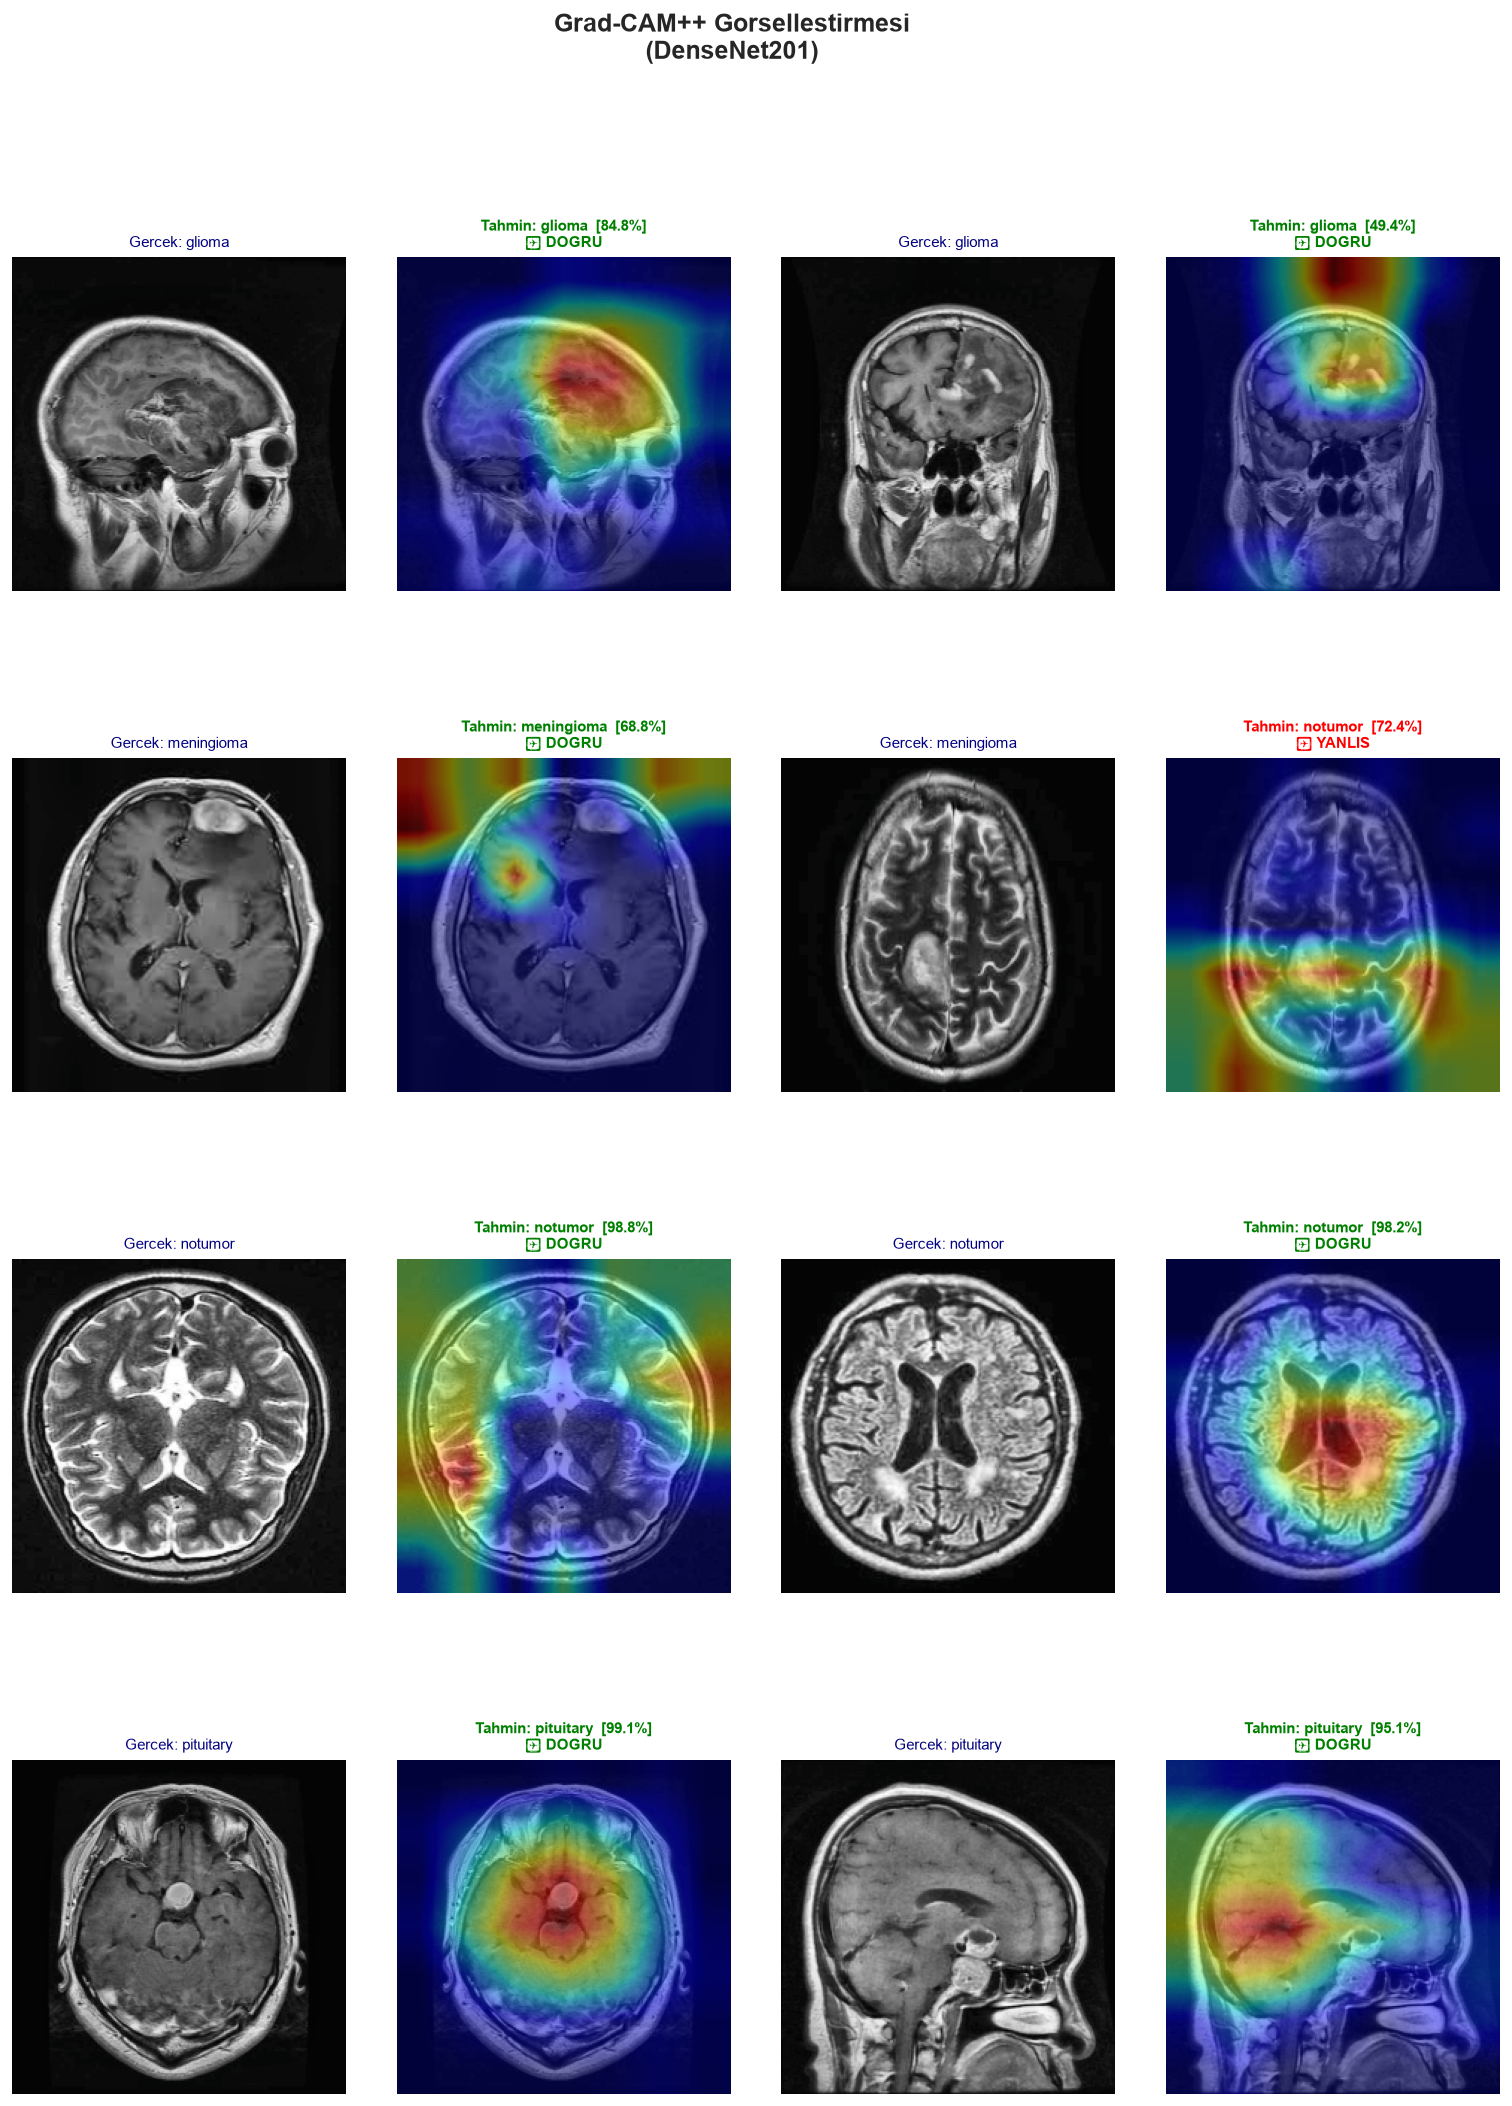

✅ Grafik kaydedildi: gradcam_plusplus.png


In [22]:
# ── Grad-CAM++ Gorsellestirmesi ──────────────────────────
# En iyi modeli sec (Ensemble haric)
solo_results   = {k: v for k, v in all_results.items()
                  if 'Ensemble' not in k}
best_name      = max(solo_results, key=lambda k: solo_results[k]['accuracy'])
best_model     = trained_models[best_name]
last_conv_name = get_last_conv_layer(best_model)

print(f"🌟 Grad-CAM++ icin secilen model : {best_name}")
print(f"   Son konvolusyon katmani       : {last_conv_name}")

# Grad-CAM icin ozel modeli olustur (Keras 3 uyumlu)
gradcam_model = build_gradcam_model(best_model, last_conv_name)

# Her siniftan 2 ornek goster (dogru ve yanlis tahminler)
NUM_SAMPLES = 2

fig = plt.figure(figsize=(16, 5 * NUM_CLASSES))
gs  = gridspec.GridSpec(NUM_CLASSES, NUM_SAMPLES * 2, hspace=0.45, wspace=0.15)
fig.suptitle(f'Grad-CAM++ Gorsellestirmesi\n({best_name})',
             fontsize=15, fontweight='bold')

for cls_idx, cls_name in enumerate(CLASSES):
    cls_test_mask = (all_results[best_name]['y_true'] == cls_idx)
    cls_indices   = np.where(cls_test_mask)[0]
    np.random.shuffle(cls_indices)
    samples = cls_indices[:NUM_SAMPLES]

    for sample_pos, idx in enumerate(samples):
        img        = X_test[idx]
        img_input  = np.expand_dims(img, axis=0)

        # Grad-CAM++ hesapla
        cam = make_gradcam_plusplus(img_input, gradcam_model)
        overlay_img = overlay_heatmap(img, cam, alpha=0.45)

        pred_idx   = all_results[best_name]['y_pred'][idx]
        true_idx   = all_results[best_name]['y_true'][idx]
        confidence = all_results[best_name]['y_prob'][idx][pred_idx]
        is_correct = (pred_idx == true_idx)

        # Orijinal goruntu
        ax_orig = fig.add_subplot(gs[cls_idx, sample_pos * 2])
        ax_orig.imshow(img)
        ax_orig.set_title(
            f'Gercek: {CLASSES[true_idx]}',
            fontsize=9, color='navy'
        )
        ax_orig.axis('off')

        # Grad-CAM++ overlay
        ax_cam  = fig.add_subplot(gs[cls_idx, sample_pos * 2 + 1])
        ax_cam.imshow(overlay_img)
        color_title = 'green' if is_correct else 'red'
        status = '✓ DOGRU' if is_correct else '✗ YANLIS'
        ax_cam.set_title(
            f'Tahmin: {CLASSES[pred_idx]}  [{confidence*100:.1f}%]\n{status}',
            fontsize=9, color=color_title, fontweight='bold'
        )
        ax_cam.axis('off')

plt.savefig('gradcam_plusplus.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik kaydedildi: gradcam_plusplus.png")

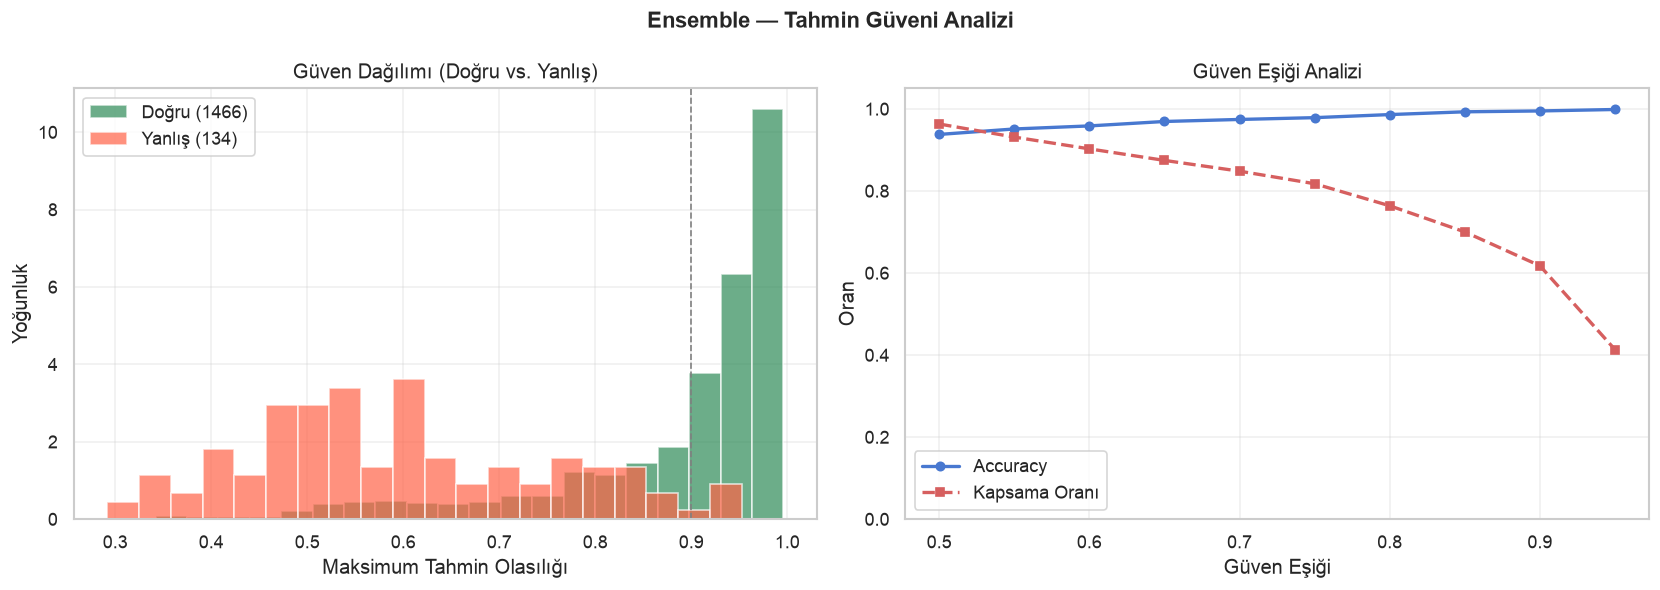

✅ Grafik kaydedildi: confidence_analysis.png

📊 Güven İstatistikleri (Ensemble):
   Doğru tahmin  ortalama güven: 0.8898
   Yanlış tahmin ortalama güven: 0.5945
   %90+ güvenle yapılan tahmin oranı: 61.8%


In [23]:
# ── 9.1 Tahmin Güveni Analizi ─────────────────────────────
# Modelin doğru/yanlış tahminlerdeki güven dağılımını karşılaştırır.
# Güven kalibrasyonu: yüksek güven = yüksek doğruluk olmalıdır.

ens_probs  = all_results['Ensemble (Weighted)']['y_prob']
ens_preds  = all_results['Ensemble (Weighted)']['y_pred']
ens_true   = all_results['Ensemble (Weighted)']['y_true']
confidence = ens_probs.max(axis=1)   # Her tahmin için maksimum olasılık

correct_mask   = ens_preds == ens_true
correct_conf   = confidence[correct_mask]
incorrect_conf = confidence[~correct_mask]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Ensemble — Tahmin Güveni Analizi', fontsize=13, fontweight='bold')

# Histogram
axes[0].hist(correct_conf,   bins=20, alpha=0.7, color='seagreen',
             label=f'Doğru ({correct_mask.sum()})', density=True)
axes[0].hist(incorrect_conf, bins=20, alpha=0.7, color='tomato',
             label=f'Yanlış ({(~correct_mask).sum()})', density=True)
axes[0].set_xlabel('Maksimum Tahmin Olasılığı')
axes[0].set_ylabel('Yoğunluk')
axes[0].set_title('Güven Dağılımı (Doğru vs. Yanlış)')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].axvline(0.9, ls='--', color='gray', lw=1, label='%90 Eşiği')

# Eşik bazlı analiz
thresholds = np.arange(0.5, 1.0, 0.05)
coverages  = []
accuracies_at_threshold = []
for thr in thresholds:
    mask = confidence >= thr
    if mask.sum() > 0:
        coverages.append(mask.mean())
        accuracies_at_threshold.append(accuracy_score(
            ens_true[mask], ens_preds[mask]))
    else:
        coverages.append(0); accuracies_at_threshold.append(1)

ax2 = axes[1]
ax2.plot(thresholds, accuracies_at_threshold, 'b-o', lw=2, ms=5, label='Accuracy')
ax2.plot(thresholds, coverages, 'r--s', lw=2, ms=5, label='Kapsama Oranı')
ax2.set_xlabel('Güven Eşiği')
ax2.set_ylabel('Oran')
ax2.set_title('Güven Eşiği Analizi')
ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig('confidence_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik kaydedildi: confidence_analysis.png")

print(f"\n📊 Güven İstatistikleri (Ensemble):")
print(f"   Doğru tahmin  ortalama güven: {correct_conf.mean():.4f}")
print(f"   Yanlış tahmin ortalama güven: {incorrect_conf.mean():.4f}")
print(f"   %90+ güvenle yapılan tahmin oranı: {(confidence>=0.90).mean()*100:.1f}%")


## 10. Sonuç ve Proje Özeti

In [24]:
# ── Final Özet Raporu ─────────────────────────────────────
print("=" * 70)
print("  🏆  PROJE SONUÇ RAPORU")
print("  MRI Görüntülerinden Beyin Tümörü Tespiti ve Sınıflandırması")
print("  230710016 – Muhammet Miraç KESER")
print("  230710054 – Cansu Naz KALKAN")
print("=" * 70)

print("\n📋 Kullanılan Yöntemler:")
print("   • Transfer Öğrenme : EfficientNetB3, DenseNet201, Xception")
print("   • İki Aşamalı Fine-Tuning : Phase 1 (dondurulmuş) + Phase 2 (son %40 serbest)")
print("   • Öğrenme Hızı Planı : Cosine Annealing with Warmup")
print("   • Kayıp Fonksiyonu : Label Smoothing CategoricalCrossentropy")
print("   • Ön İşleme : CLAHE kontrast iyileştirme + normalizasyon")
print("   • Veri Artırma : Rotasyon, kaydırma, zoom, yatay çevirme, parlaklık")
print("   • Test Zamanı Artırma : TTA (5 geçiş)")
print("   • Ensemble : Doğruluk ağırlıklı Soft-Voting")
print("   • Açıklanabilir YZ : Grad-CAM++ ısı haritaları")

print("\n📊 Test Performansı:")
print(f"   {'Model':<22} {'Accuracy':>10} {'Macro-F1':>10}")
print(f"   {'─'*22} {'─'*10} {'─'*10}")
for model_name, data in all_results.items():
    report = classification_report(
        data['y_true'], data['y_pred'],
        target_names=CLASSES, output_dict=True
    )
    macro_f1 = report['macro avg']['f1-score']
    marker = ' ← 🏆' if 'Ensemble' in model_name else ''
    print(f"   {model_name:<22} {data['accuracy']*100:>9.2f}%  {macro_f1:>9.4f}{marker}")

best_acc = all_results['Ensemble (Weighted)']['accuracy']
print(f"\n🎯 En İyi Sonuç (Ensemble): {best_acc*100:.2f}%")
print(f"   {'✅ HEDEF AŞILDI (%95)' if best_acc >= 0.95 else '⚠️  Hedef: %95+'}")

print("\n📁 Kaydedilen Dosyalar:")
saved_files = [
    'class_distribution.png', 'sample_images.png', 'augmentation_examples.png',
    'training_curves_EfficientNetB3.png', 'training_curves_DenseNet201.png',
    'training_curves_Xception.png', 'confusion_matrices.png',
    'roc_curves.png', 'model_comparison.png',
    'gradcam_plusplus.png', 'confidence_analysis.png'
]
for fname in saved_files:
    exists = '✅' if os.path.exists(fname) else '❌'
    print(f"   {exists} {fname}")

print("\n" + "=" * 70)
print("  Proje tamamlandı.")
print("=" * 70)


  🏆  PROJE SONUÇ RAPORU
  MRI Görüntülerinden Beyin Tümörü Tespiti ve Sınıflandırması
  230710016 – Muhammet Miraç KESER
  230710054 – Cansu Naz KALKAN

📋 Kullanılan Yöntemler:
   • Transfer Öğrenme : EfficientNetB3, DenseNet201, Xception
   • İki Aşamalı Fine-Tuning : Phase 1 (dondurulmuş) + Phase 2 (son %40 serbest)
   • Öğrenme Hızı Planı : Cosine Annealing with Warmup
   • Kayıp Fonksiyonu : Label Smoothing CategoricalCrossentropy
   • Ön İşleme : CLAHE kontrast iyileştirme + normalizasyon
   • Veri Artırma : Rotasyon, kaydırma, zoom, yatay çevirme, parlaklık
   • Test Zamanı Artırma : TTA (5 geçiş)
   • Ensemble : Doğruluk ağırlıklı Soft-Voting
   • Açıklanabilir YZ : Grad-CAM++ ısı haritaları

📊 Test Performansı:
   Model                    Accuracy   Macro-F1
   ────────────────────── ────────── ──────────
   EfficientNetB3             90.19%     0.8998
   DenseNet201                91.12%     0.9091
   Xception                   91.06%     0.9091
   Ensemble (Weighted)        9